In [3]:
!pip install pandas numpy matplotlib seaborn scipy statsmodels tqdm

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.optimize import curve_fit
from statsmodels.stats.diagnostic import acorr_ljungbox

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [21]:
# Change these paths to your actual file locations

message_file = r"C:\Users\ADMIN\Desktop\lob statistics\data\AMZN_2012-06-21_34200000_57600000_message_10.csv"
orderbook_file = r"C:\Users\ADMIN\Desktop\lob statistics\data\AMZN_2012-06-21_34200000_57600000_orderbook_10.csv"

# Standard LOBSTER files do not have column headers
messages = pd.read_csv(message_file, header=None)
orderbook = pd.read_csv(orderbook_file, header=None)

print("Message data shape:", messages.shape)
print("Order book shape:", orderbook.shape)

display(messages.head())
display(orderbook.head())


Message data shape: (269748, 6)
Order book shape: (269748, 40)


,0,1,2,3,4,5
0,34200.017460,5,0,1,2238200,-1
1,34200.189608,1,11885113,21,2238100,1
2,34200.189608,1,3911376,20,2239600,-1
3,34200.189608,1,11534792,100,2237500,1
4,34200.189608,1,1365373,13,2240000,-1


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39
0,2239500,100,2231800,100,2239900,100,2230700,200,2240000,220,2230400,100,2242500,100,2230000,10,2244000,547,2226200,100,2245400,100,2213000,4000,2248900,100,2204000,100,2267700,100,2202500,5000,2294300,100,2202000,100,2298000,100,2189700,100
1,2239500,100,2238100,21,2239900,100,2231800,100,2240000,220,2230700,200,2242500,100,2230400,100,2244000,547,2230000,10,2245400,100,2226200,100,2248900,100,2213000,4000,2267700,100,2204000,100,2294300,100,2202500,5000,2298000,100,2202000,100
2,2239500,100,2238100,21,2239600,20,2231800,100,2239900,100,2230700,200,2240000,220,2230400,100,2242500,100,2230000,10,2244000,547,2226200,100,2245400,100,2213000,4000,2248900,100,2204000,100,2267700,100,2202500,5000,2294300,100,2202000,100
3,2239500,100,2238100,21,2239600,20,2237500,100,2239900,100,2231800,100,2240000,220,2230700,200,2242500,100,2230400,100,2244000,547,2230000,10,2245400,100,2226200,100,2248900,100,2213000,4000,2267700,100,2204000,100,2294300,100,2202500,5000
4,2239500,100,2238100,21,2239600,20,2237500,100,2239900,100,2231800,100,2240000,233,2230700,200,2242500,100,2230400,100,2244000,547,2230000,10,2245400,100,2226200,100,2248900,100,2213000,4000,2267700,100,2204000,100,2294300,100,2202500,5000


In [23]:
messages.columns = [
    "Time",
    "Type",
    "Order_ID",
    "Size",
    "Price",
    "Direction"
]

display(messages.head())


,Time,Type,Order_ID,Size,Price,Direction
0,34200.017460,5,0,1,2238200,-1
1,34200.189608,1,11885113,21,2238100,1
2,34200.189608,1,3911376,20,2239600,-1
3,34200.189608,1,11534792,100,2237500,1
4,34200.189608,1,1365373,13,2240000,-1


In [25]:
event_types = {
    1: "New limit order",
    2: "Partial cancellation",
    3: "Order deletion",
    4: "Visible execution",
    5: "Hidden execution",
    6: "Cross trade",
    7: "Trading halt"
}

messages["Event"] = messages["Type"].map(event_types)

print(messages["Event"].value_counts(dropna=False))

Event
New limit order         131954
Order deletion          123458
Visible execution         8974
Partial cancellation      2917
Hidden execution          2445
Name: count, dtype: int64


In [15]:
direction_map = {
    1: "Buy",
    -1: "Sell"
}

messages["Side"] = messages["Direction"].map(direction_map)

print(messages["Side"].value_counts(dropna=False))

Side
Sell    139404
Buy     130344
Name: count, dtype: int64


In [27]:
print("Missing values in messages:")
print(messages.isnull().sum())

print("\nMissing values in order book:")
print(orderbook.isnull().sum())

print("\nDuplicate message rows:", messages.duplicated().sum())

print("\nFirst event time:", messages["Time"].min())
print("Last event time:", messages["Time"].max())

Missing values in messages:
Time         0
Type         0
Order_ID     0
Size         0
Price        0
Direction    0
Event        0
dtype: int64

Missing values in order book:
0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
26    0
27    0
28    0
29    0
30    0
31    0
32    0
33    0
34    0
35    0
36    0
37    0
38    0
39    0
dtype: int64

Duplicate message rows: 48

First event time: 34200.017459617
Last event time: 57599.95935965


In [29]:
print("Number of message rows:", len(messages))
print("Number of order-book rows:", len(orderbook))

if len(messages) == len(orderbook):
    print("Both files are aligned.")
else:
    print("WARNING: Row counts differ. Investigate before proceeding.")

Number of message rows: 269748
Number of order-book rows: 269748
Both files are aligned.


In [31]:
number_of_levels = orderbook.shape[1] // 4

book_columns = []

for level in range(1, number_of_levels + 1):
    book_columns.extend([
        f"Ask_Price_{level}",
        f"Ask_Volume_{level}",
        f"Bid_Price_{level}",
        f"Bid_Volume_{level}"
    ])

orderbook.columns = book_columns

print("Number of price levels:", number_of_levels)

display(orderbook.head())

Number of price levels: 10


,Ask_Price_1,Ask_Volume_1,Bid_Price_1,Bid_Volume_1,Ask_Price_2,Ask_Volume_2,Bid_Price_2,Bid_Volume_2,Ask_Price_3,Ask_Volume_3,Bid_Price_3,Bid_Volume_3,Ask_Price_4,Ask_Volume_4,Bid_Price_4,Bid_Volume_4,Ask_Price_5,Ask_Volume_5,Bid_Price_5,Bid_Volume_5,Ask_Price_6,Ask_Volume_6,Bid_Price_6,Bid_Volume_6,Ask_Price_7,Ask_Volume_7,Bid_Price_7,Bid_Volume_7,Ask_Price_8,Ask_Volume_8,Bid_Price_8,Bid_Volume_8,Ask_Price_9,Ask_Volume_9,Bid_Price_9,Bid_Volume_9,Ask_Price_10,Ask_Volume_10,Bid_Price_10,Bid_Volume_10
0,2239500,100,2231800,100,2239900,100,2230700,200,2240000,220,2230400,100,2242500,100,2230000,10,2244000,547,2226200,100,2245400,100,2213000,4000,2248900,100,2204000,100,2267700,100,2202500,5000,2294300,100,2202000,100,2298000,100,2189700,100
1,2239500,100,2238100,21,2239900,100,2231800,100,2240000,220,2230700,200,2242500,100,2230400,100,2244000,547,2230000,10,2245400,100,2226200,100,2248900,100,2213000,4000,2267700,100,2204000,100,2294300,100,2202500,5000,2298000,100,2202000,100
2,2239500,100,2238100,21,2239600,20,2231800,100,2239900,100,2230700,200,2240000,220,2230400,100,2242500,100,2230000,10,2244000,547,2226200,100,2245400,100,2213000,4000,2248900,100,2204000,100,2267700,100,2202500,5000,2294300,100,2202000,100
3,2239500,100,2238100,21,2239600,20,2237500,100,2239900,100,2231800,100,2240000,220,2230700,200,2242500,100,2230400,100,2244000,547,2230000,10,2245400,100,2226200,100,2248900,100,2213000,4000,2267700,100,2204000,100,2294300,100,2202500,5000
4,2239500,100,2238100,21,2239600,20,2237500,100,2239900,100,2231800,100,2240000,233,2230700,200,2242500,100,2230400,100,2244000,547,2230000,10,2245400,100,2226200,100,2248900,100,2213000,4000,2267700,100,2204000,100,2294300,100,2202500,5000


In [33]:
# Best ask and bid are at level 1

orderbook["Best_Ask"] = orderbook["Ask_Price_1"]
orderbook["Best_Bid"] = orderbook["Bid_Price_1"]

orderbook["Ask_Queue"] = orderbook["Ask_Volume_1"]
orderbook["Bid_Queue"] = orderbook["Bid_Volume_1"]

orderbook["Spread"] = (
    orderbook["Best_Ask"] - orderbook["Best_Bid"]
)

orderbook["Mid_Price"] = (
    orderbook["Best_Ask"] + orderbook["Best_Bid"]
) / 2

display(orderbook[
    ["Best_Bid", "Best_Ask", "Bid_Queue",
     "Ask_Queue", "Spread", "Mid_Price"]
].head())

,Best_Bid,Best_Ask,Bid_Queue,Ask_Queue,Spread,Mid_Price
0,2231800,2239500,100,100,7700,2235650.0
1,2238100,2239500,21,100,1400,2238800.0
2,2238100,2239500,21,100,1400,2238800.0
3,2238100,2239500,21,100,1400,2238800.0
4,2238100,2239500,21,100,1400,2238800.0


In [35]:
total_queue = (
    orderbook["Bid_Queue"] + orderbook["Ask_Queue"]
)

orderbook["Imbalance"] = np.where(
    total_queue > 0,
    (orderbook["Bid_Queue"] - orderbook["Ask_Queue"]) / total_queue,
    np.nan
)

display(orderbook[
    ["Bid_Queue", "Ask_Queue", "Imbalance"]
].head())

,Bid_Queue,Ask_Queue,Imbalance
0,100,100,0.000000
1,21,100,-0.652893
2,21,100,-0.652893
3,21,100,-0.652893
4,21,100,-0.652893


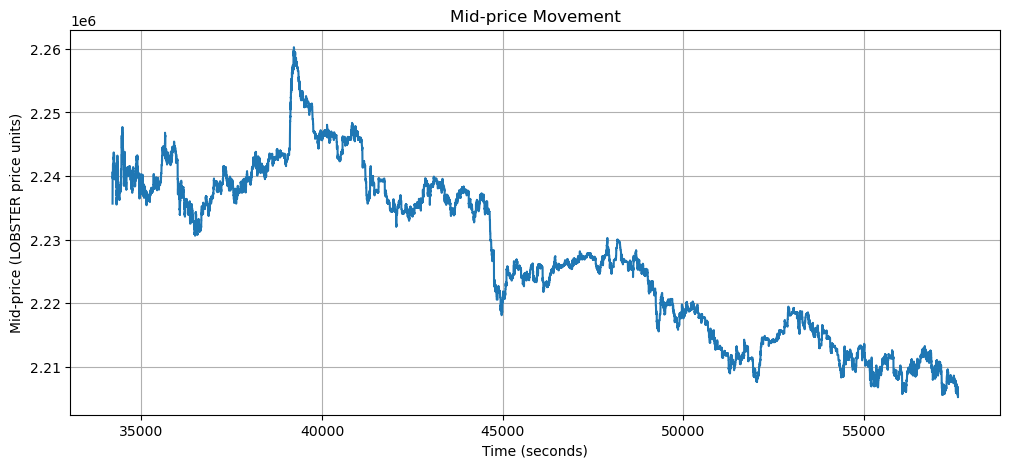

In [37]:
plt.figure(figsize=(12, 5))

plt.plot(orderbook["Time"] if "Time" in orderbook.columns
         else messages["Time"], orderbook["Mid_Price"])

plt.xlabel("Time (seconds)")
plt.ylabel("Mid-price (LOBSTER price units)")
plt.title("Mid-price Movement")
plt.grid(True)
plt.show()

Event
New limit order         131954
Order deletion          123458
Visible execution         8974
Partial cancellation      2917
Hidden execution          2445
Name: count, dtype: int64

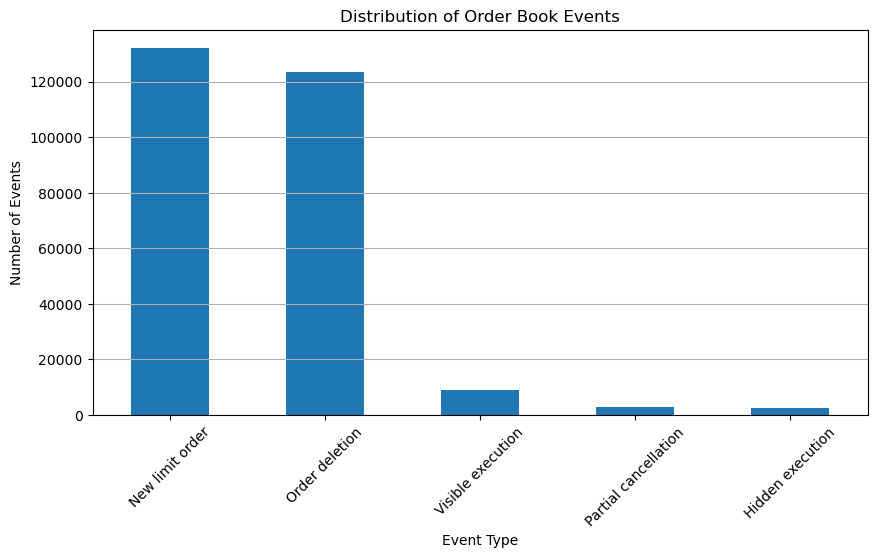

In [39]:
event_counts = messages["Event"].value_counts()

display(event_counts)

plt.figure(figsize=(10, 5))
event_counts.plot(kind="bar")

plt.title("Distribution of Order Book Events")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

In [41]:
total_time = messages["Time"].max() - messages["Time"].min()

event_rates = (
    messages.groupby("Event").size() / total_time
).sort_values(ascending=False)

print("Event arrival rates per second:")
display(event_rates)

Event arrival rates per second:


Event
New limit order         5.639074
Order deletion          5.275996
Visible execution       0.383505
Partial cancellation    0.124658
Hidden execution        0.104487
dtype: float64

In [43]:
event_data = messages.copy()

event_data["Time_Difference"] = (
    event_data.groupby("Type")["Time"].diff()
)

interarrival = event_data.dropna(
    subset=["Time_Difference"]
)

interarrival_summary = (
    interarrival.groupby("Event")["Time_Difference"]
    .agg(["mean", "std", "count"])
)

interarrival_summary["CV"] = (
    interarrival_summary["std"] /
    interarrival_summary["mean"]
)

display(interarrival_summary)

,mean,std,count,CV
Event,,,,
Hidden execution,9.573807,20.030140,2444,2.092181
New limit order,0.177334,0.501176,131953,2.826165
Order deletion,0.189538,0.542476,123457,2.862098
Partial cancellation,7.951834,49.472290,2916,6.221494
Visible execution,2.607752,7.665262,8973,2.939414


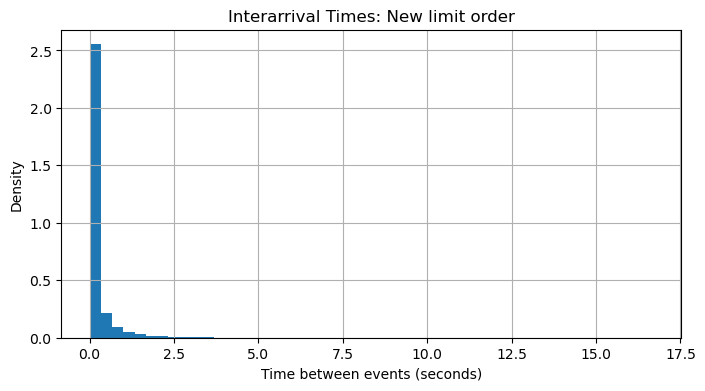

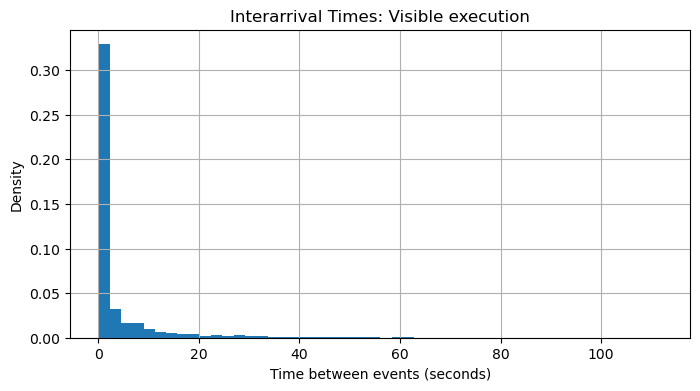

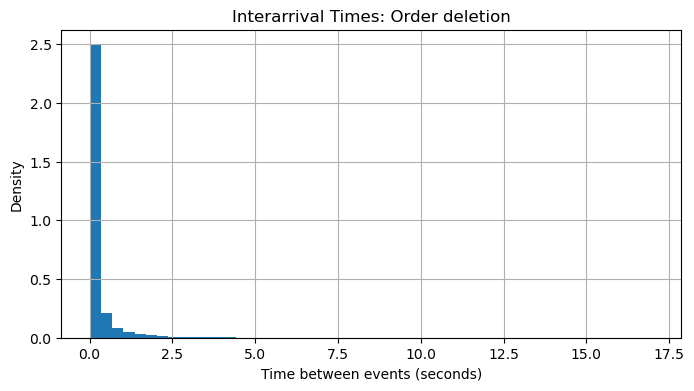

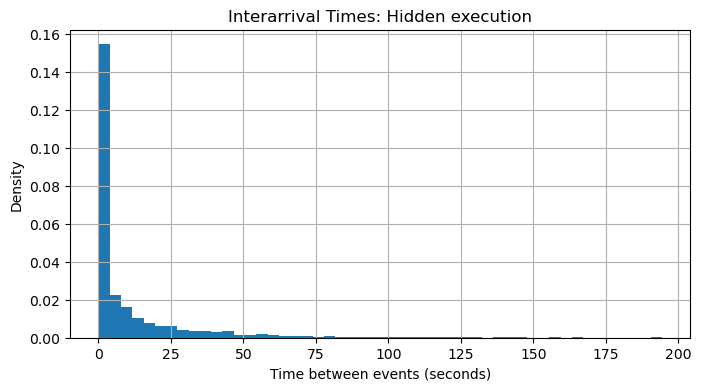

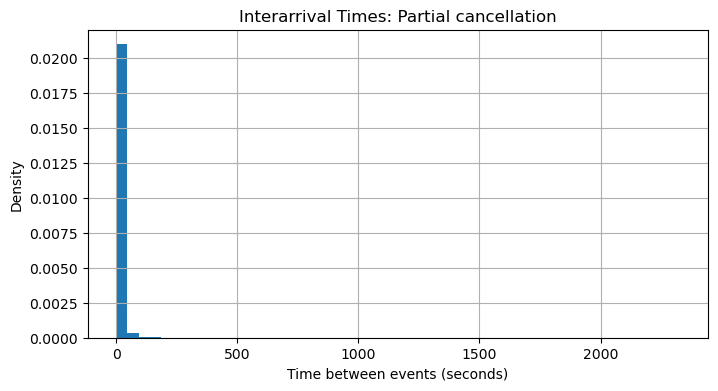

In [45]:
for event in interarrival["Event"].dropna().unique():

    data = interarrival.loc[
        interarrival["Event"] == event,
        "Time_Difference"
    ]

    data = data[data > 0]

    plt.figure(figsize=(8, 4))
    plt.hist(data, bins=50, density=True)

    plt.title(f"Interarrival Times: {event}")
    plt.xlabel("Time between events (seconds)")
    plt.ylabel("Density")
    plt.grid(True)
    plt.show()

In [ ]:
5.2 – Prepare inter-arrival times correctly

In [47]:

# ============================================
# PART 5.2: PREPARE INTER-ARRIVAL TIMES
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Work with a copy of the original message data
poisson_data = messages.copy()

# Sort events chronologically
poisson_data = poisson_data.sort_values("Time").reset_index(drop=True)

# Event descriptions
event_names = {
    1: "Limit Order Submission",
    2: "Partial Cancellation",
    3: "Order Deletion",
    4: "Visible Execution",
    5: "Hidden Execution",
    6: "Cross Trade",
    7: "Trading Halt"
}

poisson_data["Event_Name"] = poisson_data["Type"].map(event_names)

# Calculate time between consecutive events of the same type
poisson_data["Interarrival_Time"] = (
    poisson_data.groupby("Type")["Time"].diff()
)

# Remove missing and zero/negative intervals
interarrival_data = poisson_data[
    poisson_data["Interarrival_Time"] > 0
].copy()

print("Total message observations:", len(poisson_data))
print("Valid positive inter-arrival observations:",
      len(interarrival_data))

print("\nInter-arrival time summary:")

display(
    interarrival_data.groupby("Event_Name")[
        "Interarrival_Time"
    ].agg(["count", "mean", "std", "min", "max"])
)


Total message observations: 269748
Valid positive inter-arrival observations: 267056

Inter-arrival time summary:


,count,mean,std,min,max
Event_Name,,,,,
Hidden Execution,2175,10.757877,20.930978,2.171000e-06,194.395563
Limit Order Submission,131918,0.177381,0.501234,5.430047e-07,16.693860
Order Deletion,123457,0.189538,0.542476,2.509987e-07,17.021357
Partial Cancellation,2916,7.951834,49.472290,1.943001e-06,2327.382655
Visible Execution,6590,3.550737,8.755422,1.521003e-06,112.148875


In [ ]:
5.3 – Exponential distribution goodness-of-fit test

In [49]:

# ============================================
# PART 5.3: EXPONENTIAL GOODNESS-OF-FIT TEST
# ============================================

from scipy import stats

def exponential_bootstrap_test(data, B=499, random_state=42):

    x = np.asarray(data, dtype=float)

    x = x[np.isfinite(x) & (x > 0)]

    n = len(x)

    if n < 30:
        return None

    # Estimate exponential rate
    estimated_rate = 1 / np.mean(x)

    # Observed KS statistic
    observed_statistic = stats.kstest(
        x,
        "expon",
        args=(0, 1 / estimated_rate)
    ).statistic

    # Parametric bootstrap
    rng = np.random.default_rng(random_state)

    simulated_statistics = []

    for _ in range(B):

        simulated = rng.exponential(
            scale=1 / estimated_rate,
            size=n
        )

        # Re-estimate the parameter in every sample
        simulated_rate = 1 / np.mean(simulated)

        simulated_statistic = stats.kstest(
            simulated,
            "expon",
            args=(0, 1 / simulated_rate)
        ).statistic

        simulated_statistics.append(simulated_statistic)

    # Bootstrap p-value
    p_value = (
        1 + np.sum(
            np.asarray(simulated_statistics) >= observed_statistic
        )
    ) / (B + 1)

    return {
        "Observations": n,
        "Estimated_Rate": estimated_rate,
        "KS_Statistic": observed_statistic,
        "Bootstrap_P_Value": p_value
    }


# Test each event category
exponential_results = []

for event_type in sorted(poisson_data["Type"].dropna().unique()):

    event_name = event_names.get(event_type, str(event_type))

    sample = interarrival_data.loc[
        interarrival_data["Type"] == event_type,
        "Interarrival_Time"
    ]

    result = exponential_bootstrap_test(sample)

    if result is not None:

        result["Event"] = event_name

        exponential_results.append(result)


exponential_results_df = pd.DataFrame(exponential_results)

print("EXPONENTIAL DISTRIBUTION TEST RESULTS")

display(exponential_results_df)


EXPONENTIAL DISTRIBUTION TEST RESULTS


,Observations,Estimated_Rate,KS_Statistic,Bootstrap_P_Value,Event
0,131918,5.637577,0.514119,0.002,Limit Order Submission
1,2916,0.125757,0.323041,0.002,Partial Cancellation
2,123457,5.275993,0.495894,0.002,Order Deletion
3,6590,0.281632,0.504591,0.002,Visible Execution
4,2175,0.092955,0.366149,0.002,Hidden Execution


In [ ]:
5.4 – Test the Poisson arrival assumption

In [51]:

# ============================================
# PART 5.4: POISSON ARRIVAL TEST
# ============================================

poisson_count_results = []

start_time = poisson_data["Time"].min()

# Create one-second time intervals
poisson_data["Time_Bin"] = np.floor(
    poisson_data["Time"] - start_time
).astype(int)

for event_type in sorted(poisson_data["Type"].dropna().unique()):

    event_name = event_names.get(event_type, str(event_type))

    event_subset = poisson_data[
        poisson_data["Type"] == event_type
    ]

    # Count events in each one-second interval
    counts = (
        event_subset.groupby("Time_Bin")
        .size()
        .reindex(
            range(
                int(np.ceil(
                    poisson_data["Time"].max() - start_time
                ))
            ),
            fill_value=0
        )
    )

    mean_count = counts.mean()
    variance_count = counts.var()

    dispersion_ratio = (
        variance_count / mean_count
        if mean_count > 0 else np.nan
    )

    # Chi-square dispersion diagnostic
    if mean_count > 0 and len(counts) > 1:

        chi_square = (
            (len(counts) - 1) * dispersion_ratio
        )

        p_value = stats.chi2.sf(
            chi_square,
            df=len(counts) - 1
        )

    else:
        chi_square = np.nan
        p_value = np.nan

    poisson_count_results.append({
        "Event": event_name,
        "Mean_Count": mean_count,
        "Variance_Count": variance_count,
        "Dispersion_Ratio": dispersion_ratio,
        "Chi_Square": chi_square,
        "P_Value": p_value
    })


poisson_count_results_df = pd.DataFrame(
    poisson_count_results
)

print("POISSON COUNT DISPERSION RESULTS")

display(poisson_count_results_df)


POISSON COUNT DISPERSION RESULTS


,Event,Mean_Count,Variance_Count,Dispersion_Ratio,Chi_Square,P_Value
0,Limit Order Submission,5.639060,82.413073,14.614683,341968.973157,0.0
1,Partial Cancellation,0.124658,0.241180,1.934732,45270.795680,0.0
2,Order Deletion,5.275983,73.627322,13.955186,326537.392765,0.0
3,Visible Execution,0.383504,3.674022,9.580132,224165.514152,0.0
4,Hidden Execution,0.104487,0.371278,3.553333,83144.447853,0.0


In [ ]:
5.5 – Test independence of inter-arrival times

In [53]:

# ============================================
# PART 5.5: LJUNG-BOX AUTOCORRELATION TEST
# ============================================

from statsmodels.stats.diagnostic import acorr_ljungbox

autocorrelation_results = []

for event_type in sorted(poisson_data["Type"].dropna().unique()):

    event_name = event_names.get(event_type, str(event_type))

    sample = interarrival_data.loc[
        interarrival_data["Type"] == event_type,
        "Interarrival_Time"
    ].dropna()

    # Avoid excessive computation
    if len(sample) < 50:
        continue

    sample = sample.iloc[:20000]

    # Ljung-Box test at lag 10
    result = acorr_ljungbox(
        sample,
        lags=[10],
        return_df=True
    )

    autocorrelation_results.append({
        "Event": event_name,
        "Observations": len(sample),
        "Ljung_Box_Statistic": result["lb_stat"].iloc[0],
        "P_Value": result["lb_pvalue"].iloc[0]
    })


autocorrelation_results_df = pd.DataFrame(
    autocorrelation_results
)

print("INTER-ARRIVAL INDEPENDENCE TEST")

display(autocorrelation_results_df)


INTER-ARRIVAL INDEPENDENCE TEST


,Event,Observations,Ljung_Box_Statistic,P_Value
0,Limit Order Submission,20000,2453.000939,0.000000e+00
1,Partial Cancellation,2916,712.069384,1.609714e-146
2,Order Deletion,20000,3189.606651,0.000000e+00
3,Visible Execution,6590,475.025211,9.538197e-96
4,Hidden Execution,2175,351.062415,2.370959e-69


In [ ]:
5.6 – Visualise the exponential distribution

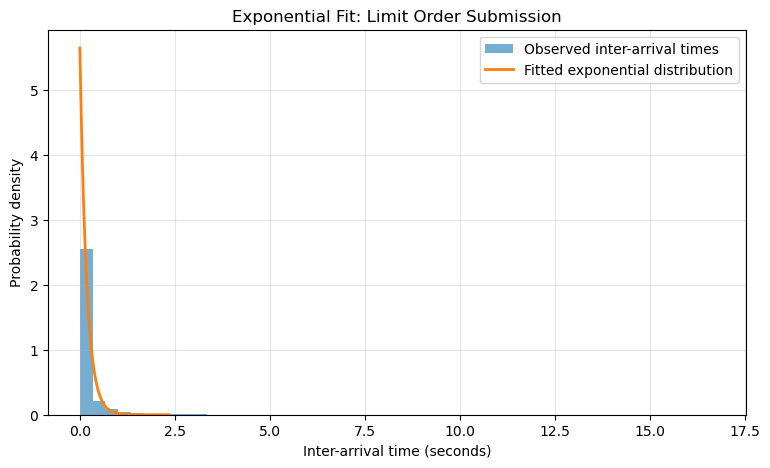

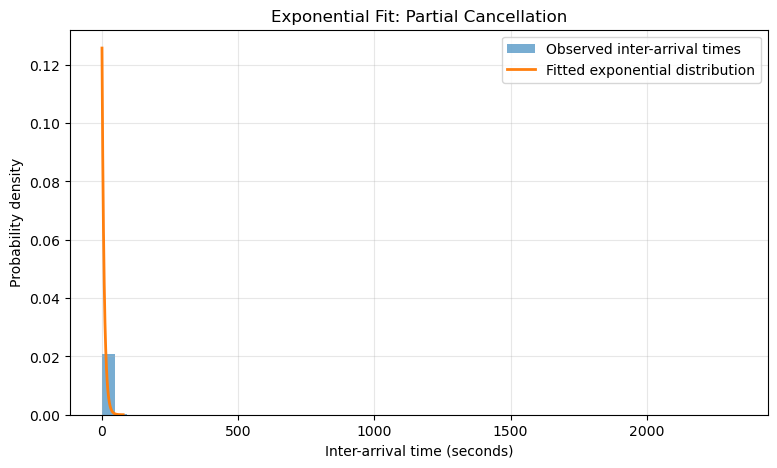

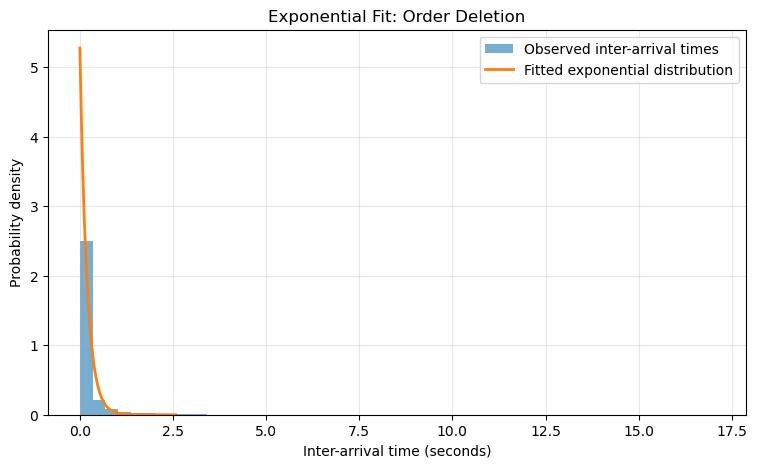

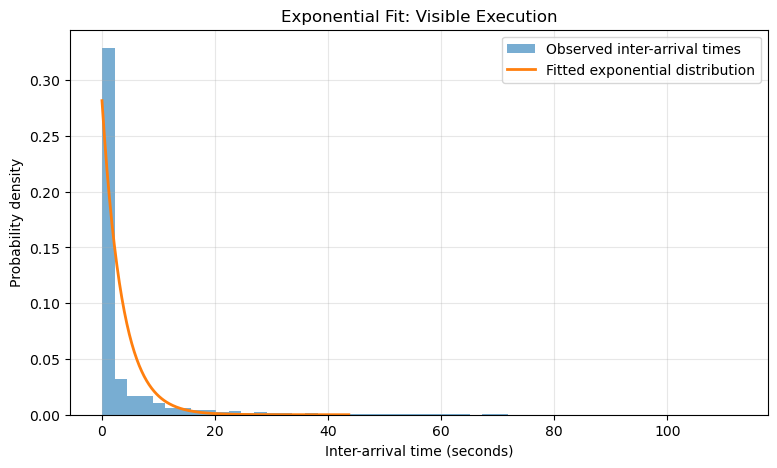

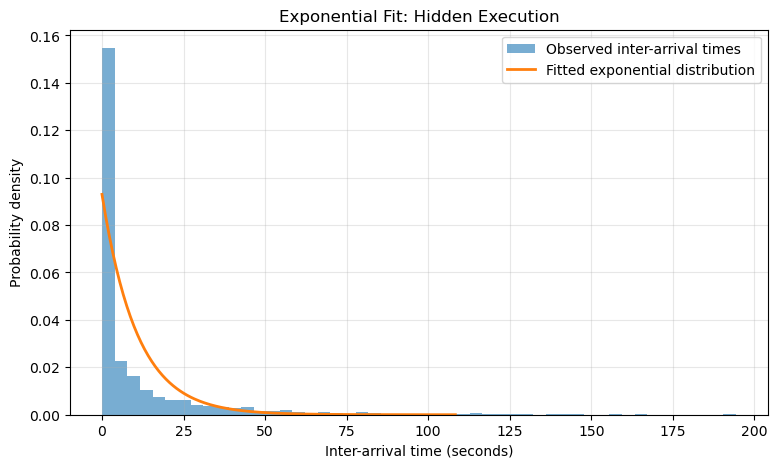

In [55]:

# ============================================
# PART 5.6: EXPONENTIAL DISTRIBUTION PLOTS
# ============================================

for event_type in sorted(poisson_data["Type"].dropna().unique()):

    event_name = event_names.get(event_type, str(event_type))

    sample = interarrival_data.loc[
        interarrival_data["Type"] == event_type,
        "Interarrival_Time"
    ].dropna()

    if len(sample) < 30:
        continue

    rate = 1 / sample.mean()

    x = np.linspace(
        0,
        sample.quantile(0.99),
        200
    )

    theoretical_density = stats.expon.pdf(
        x,
        scale=1 / rate
    )

    plt.figure(figsize=(9, 5))

    plt.hist(
        sample,
        bins=50,
        density=True,
        alpha=0.6,
        label="Observed inter-arrival times"
    )

    plt.plot(
        x,
        theoretical_density,
        linewidth=2,
        label="Fitted exponential distribution"
    )

    plt.title(
        f"Exponential Fit: {event_name}"
    )

    plt.xlabel("Inter-arrival time (seconds)")
    plt.ylabel("Probability density")

    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


In [57]:

# ============================================
# PART 5.7: EXPORT STATISTICAL RESULTS
# ============================================

exponential_results_df.to_csv(
    "exponential_test_results.csv",
    index=False
)

poisson_count_results_df.to_csv(
    "poisson_test_results.csv",
    index=False
)

autocorrelation_results_df.to_csv(
    "autocorrelation_test_results.csv",
    index=False
)

print("Part 5 statistical results saved successfully.")

print("\nFiles created:")
print("1. exponential_test_results.csv")
print("2. poisson_test_results.csv")
print("3. autocorrelation_test_results.csv")



Part 5 statistical results saved successfully.

Files created:
1. exponential_test_results.csv
2. poisson_test_results.csv
3. autocorrelation_test_results.csv


In [ ]:
6.1 Prepare the order-book states

Prepared event observations: 269747

TIME SPENT IN EACH SPREAD STATE


,Spread_Ticks,Time_in_State
0,1.0,55.063831
1,2.0,86.393486
2,3.0,193.398832
3,4.0,355.718796
4,5.0,562.095234
...,...,...
62,68.0,3.022052
63,69.0,4.447881
64,73.0,3.587332
65,74.0,0.000000



ORDER DISTANCE SUMMARY


,Distance_Ticks
count,269747.000000
mean,19.620200
std,7.709573
min,0.000000
25%,15.000000
50%,20.000000
75%,24.000000
max,385.000000



LIMIT ORDER ARRIVAL RATES


,Spread_Ticks,Direction,Distance_Ticks,Arrival_Count,Average_Limit_Size,Total_Limit_Size,Time_in_State,Arrival_Rate,Side,Reliable_Count
0,1,-1,1.0,94,94.510638,8884,55.063831,1.707110,Sell,True
23,1,1,1.0,75,97.520000,7314,55.063831,1.362056,Buy,True
1,1,-1,2.0,11,91.454545,1006,55.063831,0.199768,Sell,True
24,1,1,2.0,2,250.000000,500,55.063831,0.036321,Buy,False
2,1,-1,3.0,4,76.000000,304,55.063831,0.072643,Sell,False
25,1,1,3.0,3,100.000000,300,55.063831,0.054482,Buy,False
3,1,-1,4.0,7,74.285714,520,55.063831,0.127125,Sell,True
26,1,1,4.0,2,100.000000,200,55.063831,0.036321,Buy,False
4,1,-1,5.0,4,32.250000,129,55.063831,0.072643,Sell,False
27,1,1,5.0,1,200.000000,200,55.063831,0.018161,Buy,False


... (6 outputs left out)


SUMMARY: MARKET ORDER RATES


Market_Rate_Raw                     Market_Rate_Adjusted                    
               count      mean    median                count      mean    median
Side                                                                             
Buy               44  0.590432  0.241955                   44  0.439015  0.159018
Sell              33  0.432837  0.173030                   33  0.325995  0.097223


SUMMARY: CANCELLATION RATES


,count,mean,median,std
Side,,,,
Buy,1172,1.220843,0.040956,19.320826
Sell,1229,0.111795,0.050719,0.327931


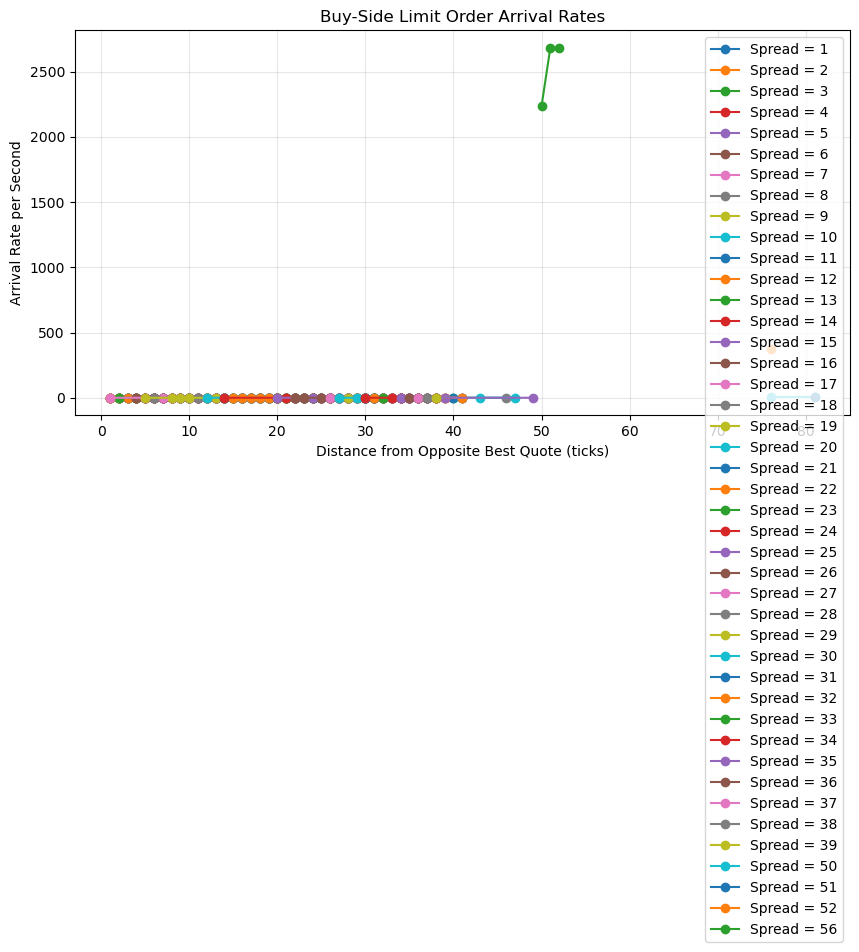

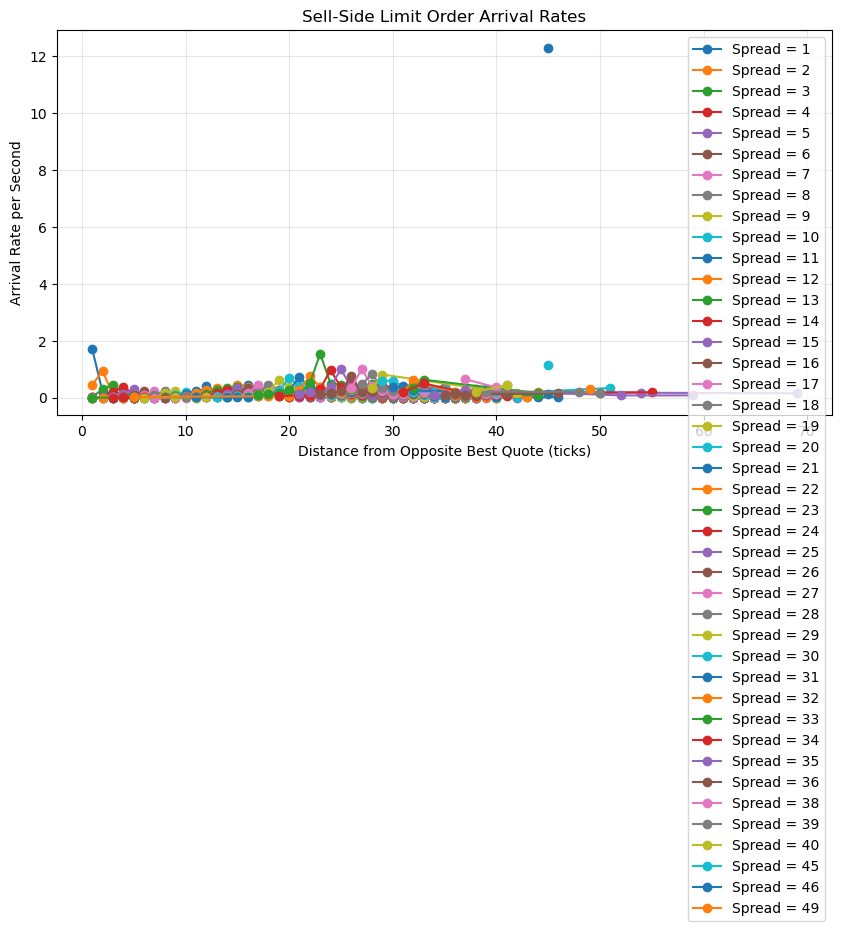

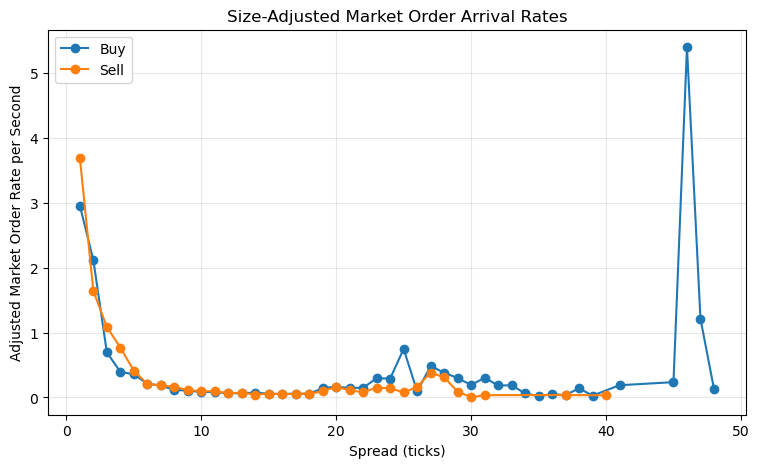

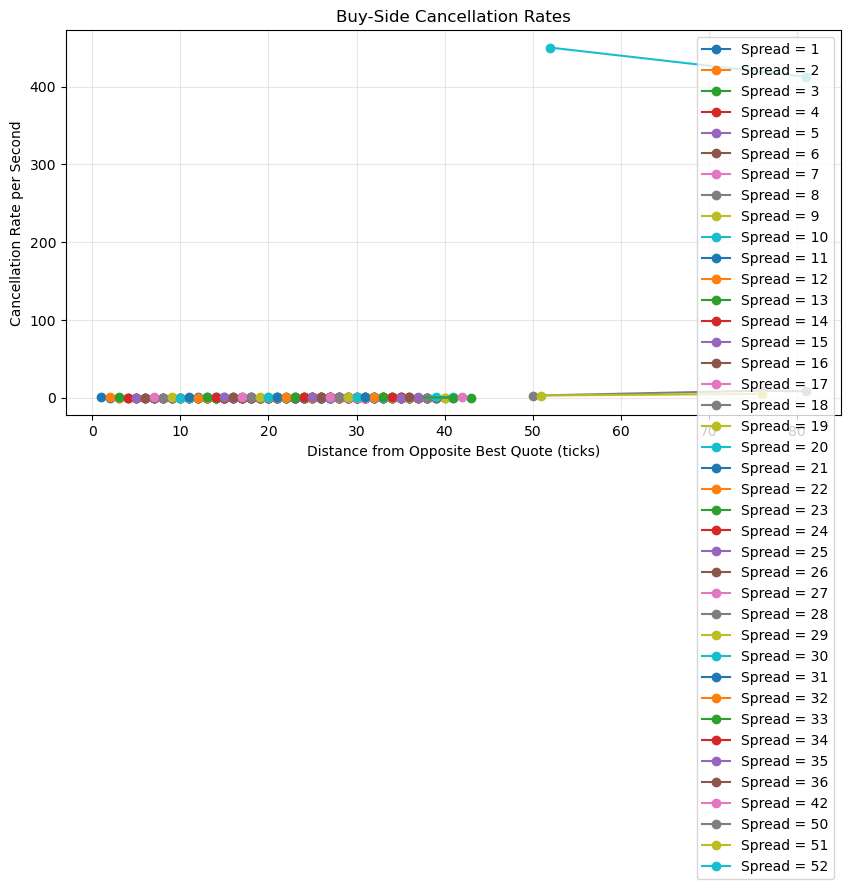

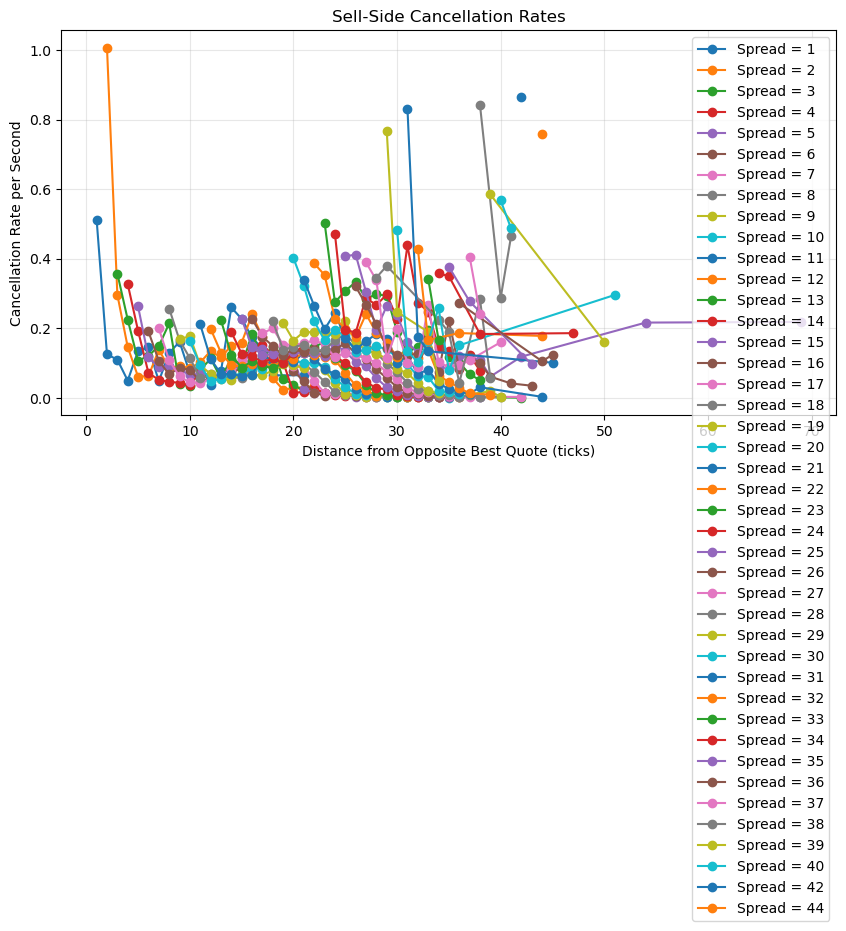


PART 6 COMPLETED
Saved files:
1. spread_state_durations.csv
2. limit_order_arrival_rates.csv
3. market_order_arrival_rates.csv
4. cancellation_rates.csv
5. average_queue_volumes.csv


In [71]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PART 6: STATE-DEPENDENT ORDER-FLOW PARAMETER ESTIMATION
# ============================================================
#
# Requires the following from Part 6.1:
# messages, orderbook, analysis_messages, pre_book
#
# LOBSTER event types:
# 1 = Limit order submission
# 2 = Partial cancellation
# 3 = Order deletion
# 4 = Visible execution
# 5 = Hidden execution
#
# Direction:
# +1 = Buy
# -1 = Sell
#
# ============================================================

# ------------------------------------------------------------
# 6.0 VERIFY INPUTS
# ------------------------------------------------------------

required_columns = [
    "Time", "Type", "Size", "Price", "Direction"
]

for col in required_columns:
    if col not in analysis_messages.columns:
        raise ValueError(
            f"Column {col} is missing from analysis_messages."
        )

if len(pre_book) != len(analysis_messages):
    raise ValueError(
        "pre_book and analysis_messages have different lengths."
    )

TICK_SIZE = 100.0

# Set a minimum observation threshold for displaying
# estimated rates. Raw estimates are still retained.
MIN_STATE_EVENTS = 5

# ------------------------------------------------------------
# 6.1 PREPARE DATA
# ------------------------------------------------------------

data = analysis_messages.copy().reset_index(drop=True)
book_data = pre_book.copy().reset_index(drop=True)

for col in required_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data[
    data["Direction"].isin([1, -1])
    & data["Type"].notna()
    & data["Size"].notna()
    & (data["Size"] >= 0)
].copy()

data = data.reset_index(drop=True)

# Check spread and calculate integer spread ticks.
data["Spread_Ticks"] = (
    (
        data["Pre_Best_Ask"] - data["Pre_Best_Bid"]
    ) / TICK_SIZE
).round()

data = data[
    (data["Spread_Ticks"] > 0)
    & data["Spread_Ticks"].notna()
].copy()

data["Spread_Ticks"] = data["Spread_Ticks"].astype(int)

print("Prepared event observations:", len(data))

# ------------------------------------------------------------
# 6.2 ESTIMATE TIME SPENT IN EACH SPREAD STATE
# ------------------------------------------------------------

# State immediately before each event.
# The duration is measured until the next event timestamp.

all_times = pd.to_numeric(
    messages["Time"], errors="coerce"
).to_numpy(dtype=float)

if not np.all(np.isfinite(all_times)):
    raise ValueError("Invalid timestamps found in messages.")

if np.any(np.diff(all_times) < 0):
    raise ValueError("Message timestamps are not sorted.")

# The state in pre_book row i applies to message i+1.
state_spreads = (
    (
        pd.to_numeric(book_data["Ask_Price_1"], errors="coerce")
        - pd.to_numeric(book_data["Bid_Price_1"], errors="coerce")
    ) / TICK_SIZE
).round()

# Duration after each event, ending at the next event.
# First message's state is not represented in analysis_messages.
duration_values = np.diff(all_times)[1:]

state_duration = pd.DataFrame({
    "Spread_Ticks": state_spreads.iloc[1:].to_numpy(),
    "Duration": duration_values
})

state_duration = state_duration[
    state_duration["Spread_Ticks"].notna()
    & (state_duration["Spread_Ticks"] > 0)
    & (state_duration["Duration"] >= 0)
].copy()

spread_time = (
    state_duration.groupby("Spread_Ticks")["Duration"]
    .sum()
    .rename("Time_in_State")
    .reset_index()
)

print("\nTIME SPENT IN EACH SPREAD STATE")
display(spread_time)

# ------------------------------------------------------------
# 6.3 CALCULATE DISTANCE FROM OPPOSITE BEST QUOTE
# ------------------------------------------------------------

data["Distance_Ticks"] = np.nan

buy_mask = data["Direction"] == 1
sell_mask = data["Direction"] == -1

# Buy order: distance from best ask.
data.loc[buy_mask, "Distance_Ticks"] = (
    data.loc[buy_mask, "Pre_Best_Ask"]
    - data.loc[buy_mask, "Price"]
) / TICK_SIZE

# Sell order: distance from best bid.
data.loc[sell_mask, "Distance_Ticks"] = (
    data.loc[sell_mask, "Price"]
    - data.loc[sell_mask, "Pre_Best_Bid"]
) / TICK_SIZE

data["Distance_Ticks"] = data["Distance_Ticks"].round()

print("\nORDER DISTANCE SUMMARY")
display(data["Distance_Ticks"].describe().to_frame())

# ------------------------------------------------------------
# 6.4 LIMIT ORDER ARRIVAL RATES
# ------------------------------------------------------------

limit_orders = data[
    (data["Type"] == 1)
    & data["Distance_Ticks"].notna()
    & (data["Distance_Ticks"] >= 0)
].copy()

limit_counts = (
    limit_orders.groupby(
        ["Spread_Ticks", "Direction", "Distance_Ticks"]
    )
    .agg(
        Arrival_Count=("Type", "size"),
        Average_Limit_Size=("Size", "mean"),
        Total_Limit_Size=("Size", "sum")
    )
    .reset_index()
)

limit_rates = limit_counts.merge(
    spread_time,
    on="Spread_Ticks",
    how="left"
)

# Raw event arrival rate per second.
limit_rates["Arrival_Rate"] = (
    limit_rates["Arrival_Count"]
    / limit_rates["Time_in_State"]
)

# Side labels.
limit_rates["Side"] = limit_rates["Direction"].map({
    1: "Buy",
    -1: "Sell"
})

# Flag estimates based on small numbers of events.
limit_rates["Reliable_Count"] = (
    limit_rates["Arrival_Count"] >= MIN_STATE_EVENTS
)

print("\nLIMIT ORDER ARRIVAL RATES")
display(
    limit_rates.sort_values(
        ["Spread_Ticks", "Distance_Ticks", "Direction"]
    ).head(50)
)

# ------------------------------------------------------------
# 6.5 MARKET ORDER ARRIVAL RATES
# ------------------------------------------------------------

# Type 4 = visible execution.
# The aggressor side is opposite to the resting order side.

market_orders = data[
    (data["Type"] == 4)
    & data["Direction"].isin([1, -1])
].copy()

market_orders["Market_Direction"] = (
    -market_orders["Direction"]
)

market_counts = (
    market_orders.groupby(
        ["Spread_Ticks", "Market_Direction"]
    )
    .agg(
        Market_Count=("Type", "size"),
        Average_Market_Size=("Size", "mean"),
        Total_Market_Size=("Size", "sum")
    )
    .reset_index()
)

# Average limit order size by spread.
average_limit_size = (
    limit_orders.groupby("Spread_Ticks")["Size"]
    .mean()
    .rename("Average_Limit_Size")
    .reset_index()
)

market_rates = (
    market_counts
    .merge(spread_time, on="Spread_Ticks", how="left")
    .merge(average_limit_size, on="Spread_Ticks", how="left")
)

# Paper-inspired adjustment for different order sizes.
market_rates["Market_Size_Ratio"] = (
    market_rates["Average_Market_Size"]
    / market_rates["Average_Limit_Size"]
)

market_rates["Market_Rate_Raw"] = (
    market_rates["Market_Count"]
    / market_rates["Time_in_State"]
)

market_rates["Market_Rate_Adjusted"] = (
    market_rates["Market_Rate_Raw"]
    * market_rates["Market_Size_Ratio"]
)

market_rates["Side"] = market_rates["Market_Direction"].map({
    1: "Buy",
    -1: "Sell"
})

market_rates["Reliable_Count"] = (
    market_rates["Market_Count"] >= MIN_STATE_EVENTS
)

print("\nMARKET ORDER ARRIVAL RATES")
display(market_rates)

# ------------------------------------------------------------
# 6.6 CANCELLATION RATES
# ------------------------------------------------------------

# Types 2 and 3 are combined:
# Type 2 = partial cancellation
# Type 3 = order deletion

cancellations = data[
    data["Type"].isin([2, 3])
    & data["Distance_Ticks"].notna()
    & (data["Distance_Ticks"] >= 0)
].copy()

cancellation_volume = (
    cancellations.groupby(
        ["Spread_Ticks", "Direction", "Distance_Ticks"]
    )
    .agg(
        Cancellation_Count=("Type", "size"),
        Cancelled_Volume=("Size", "sum"),
        Average_Cancellation_Size=("Size", "mean")
    )
    .reset_index()
)

# ------------------------------------------------------------
# Calculate average queue volume at each spread,
# side and distance from the opposite best quote.
# ------------------------------------------------------------

queue_records = []

# Work from pre-event snapshots.
# Keep this loop straightforward and explicit.

for i in range(len(book_data)):

    row = book_data.iloc[i]

    ask_prices = np.array([
        row[f"Ask_Price_{level}"]
        for level in range(1, 11)
    ], dtype=float)

    ask_volumes = np.array([
        row[f"Ask_Volume_{level}"]
        for level in range(1, 11)
    ], dtype=float)

    bid_prices = np.array([
        row[f"Bid_Price_{level}"]
        for level in range(1, 11)
    ], dtype=float)

    bid_volumes = np.array([
        row[f"Bid_Volume_{level}"]
        for level in range(1, 11)
    ], dtype=float)

    best_ask = ask_prices[0]
    best_bid = bid_prices[0]

    if (
        not np.isfinite(best_ask)
        or not np.isfinite(best_bid)
        or best_ask <= best_bid
    ):
        continue

    spread = int(round(
        (best_ask - best_bid) / TICK_SIZE
    ))

    # Bid queue: direction +1.
    for j in range(10):

        price = bid_prices[j]
        volume = bid_volumes[j]

        if (
            np.isfinite(price)
            and np.isfinite(volume)
            and price > 0
            and volume > 0
        ):

            distance = int(round(
                (best_ask - price) / TICK_SIZE
            ))

            queue_records.append({
                "Spread_Ticks": spread,
                "Direction": 1,
                "Distance_Ticks": distance,
                "Queue_Volume": volume
            })

    # Ask queue: direction -1.
    for j in range(10):

        price = ask_prices[j]
        volume = ask_volumes[j]

        if (
            np.isfinite(price)
            and np.isfinite(volume)
            and price > 0
            and volume > 0
        ):

            distance = int(round(
                (price - best_bid) / TICK_SIZE
            ))

            queue_records.append({
                "Spread_Ticks": spread,
                "Direction": -1,
                "Distance_Ticks": distance,
                "Queue_Volume": volume
            })

queue_data = pd.DataFrame(queue_records)

if queue_data.empty:
    raise ValueError(
        "No valid queue observations were found. "
        "Check book columns and tick size."
    )

average_queue = (
    queue_data.groupby(
        ["Spread_Ticks", "Direction", "Distance_Ticks"]
    )["Queue_Volume"]
    .mean()
    .rename("Average_Queue_Volume")
    .reset_index()
)

# ------------------------------------------------------------
# Calculate cancellation intensity.
# ------------------------------------------------------------

cancellation_rates = (
    cancellation_volume
    .merge(
        average_queue,
        on=[
            "Spread_Ticks",
            "Direction",
            "Distance_Ticks"
        ],
        how="left"
    )
    .merge(
        spread_time,
        on="Spread_Ticks",
        how="left"
    )
)

# Cancellation volume per second divided by
# average displayed queue volume.
cancellation_rates["Cancellation_Rate"] = (
    cancellation_rates["Cancelled_Volume"]
    / (
        cancellation_rates["Time_in_State"]
        * cancellation_rates["Average_Queue_Volume"]
    )
)

cancellation_rates["Side"] = (
    cancellation_rates["Direction"].map({
        1: "Buy",
        -1: "Sell"
    })
)

cancellation_rates["Reliable_Count"] = (
    cancellation_rates["Cancellation_Count"]
    >= MIN_STATE_EVENTS
)

print("\nCANCELLATION RATES")
display(
    cancellation_rates.sort_values(
        ["Spread_Ticks", "Distance_Ticks", "Direction"]
    ).head(50)
)

# ------------------------------------------------------------
# 6.7 SUMMARY OF PARAMETER ESTIMATES
# ------------------------------------------------------------

print("\nSUMMARY: LIMIT ORDER RATES")
display(
    limit_rates.groupby("Side")["Arrival_Rate"]
    .agg(["count", "mean", "median", "std"])
)

print("\nSUMMARY: MARKET ORDER RATES")
display(
    market_rates.groupby("Side")[
        ["Market_Rate_Raw", "Market_Rate_Adjusted"]
    ].agg(["count", "mean", "median"])
)

print("\nSUMMARY: CANCELLATION RATES")
display(
    cancellation_rates.groupby("Side")["Cancellation_Rate"]
    .agg(["count", "mean", "median", "std"])
)

# ------------------------------------------------------------
# 6.8 PLOT LIMIT ORDER ARRIVAL RATES
# ------------------------------------------------------------

for side in ["Buy", "Sell"]:

    subset = limit_rates[
        (limit_rates["Side"] == side)
        & limit_rates["Reliable_Count"]
    ]

    if subset.empty:
        print(f"No sufficiently populated limit states for {side}.")
        continue

    plt.figure(figsize=(10, 5))

    for spread in sorted(subset["Spread_Ticks"].unique()):

        temp = subset[
            subset["Spread_Ticks"] == spread
        ].sort_values("Distance_Ticks")

        plt.plot(
            temp["Distance_Ticks"],
            temp["Arrival_Rate"],
            marker="o",
            label=f"Spread = {spread}"
        )

    plt.title(f"{side}-Side Limit Order Arrival Rates")
    plt.xlabel("Distance from Opposite Best Quote (ticks)")
    plt.ylabel("Arrival Rate per Second")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

# ------------------------------------------------------------
# 6.9 PLOT MARKET ORDER RATES
# ------------------------------------------------------------

if not market_rates.empty:

    plt.figure(figsize=(9, 5))

    for side in ["Buy", "Sell"]:

        temp = market_rates[
            market_rates["Side"] == side
        ].sort_values("Spread_Ticks")

        plt.plot(
            temp["Spread_Ticks"],
            temp["Market_Rate_Adjusted"],
            marker="o",
            label=side
        )

    plt.title("Size-Adjusted Market Order Arrival Rates")
    plt.xlabel("Spread (ticks)")
    plt.ylabel("Adjusted Market Order Rate per Second")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

# ------------------------------------------------------------
# 6.10 PLOT CANCELLATION RATES
# ------------------------------------------------------------

for side in ["Buy", "Sell"]:

    subset = cancellation_rates[
        (cancellation_rates["Side"] == side)
        & cancellation_rates["Reliable_Count"]
        & cancellation_rates["Cancellation_Rate"].notna()
    ]

    if subset.empty:
        print(f"No sufficiently populated cancellation states for {side}.")
        continue

    plt.figure(figsize=(10, 5))

    for spread in sorted(subset["Spread_Ticks"].unique()):

        temp = subset[
            subset["Spread_Ticks"] == spread
        ].sort_values("Distance_Ticks")

        plt.plot(
            temp["Distance_Ticks"],
            temp["Cancellation_Rate"],
            marker="o",
            label=f"Spread = {spread}"
        )

    plt.title(f"{side}-Side Cancellation Rates")
    plt.xlabel("Distance from Opposite Best Quote (ticks)")
    plt.ylabel("Cancellation Rate per Second")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

# ------------------------------------------------------------
# 6.11 SAVE ALL ESTIMATED PARAMETERS
# ------------------------------------------------------------

spread_time.to_csv(
    "spread_state_durations.csv",
    index=False
)

limit_rates.to_csv(
    "limit_order_arrival_rates.csv",
    index=False
)

market_rates.to_csv(
    "market_order_arrival_rates.csv",
    index=False
)

cancellation_rates.to_csv(
    "cancellation_rates.csv",
    index=False
)

average_queue.to_csv(
    "average_queue_volumes.csv",
    index=False
)

print("\n================================================")
print("PART 6 COMPLETED")
print("================================================")

print("Saved files:")
print("1. spread_state_durations.csv")
print("2. limit_order_arrival_rates.csv")
print("3. market_order_arrival_rates.csv")
print("4. cancellation_rates.csv")
print("5. average_queue_volumes.csv")


In [81]:

# ------------------------------------------------------------
# FIND THE ACTUAL PART 6 DATAFRAME VARIABLE NAMES
# ------------------------------------------------------------

import pandas as pd

print("DATAFRAMES AVAILABLE IN YOUR NOTEBOOK")
print("=" * 75)

for variable_name, variable_value in list(globals().items()):

    if isinstance(variable_value, pd.DataFrame):

        print(f"\nVariable name: {variable_name}")
        print(f"Shape: {variable_value.shape}")
        print("Columns:", variable_value.columns.tolist())

        if any(
            word in variable_name.lower()
            for word in ["limit", "market", "cancel", "rate"]
        ):
            print("\nFirst 5 rows:")
            print(variable_value.head().to_string(index=False))


DATAFRAMES AVAILABLE IN YOUR NOTEBOOK

Variable name: _
Shape: (20, 11)
Columns: ['Spread_Ticks', 'Direction', 'Distance_Ticks', 'Cancellation_Count', 'Cancelled_Volume', 'Average_Cancellation_Size', 'Average_Queue_Volume', 'Time_in_State', 'Cancellation_Rate', 'Side', 'Reliable_Count']

Variable name: __
Shape: (77, 12)
Columns: ['Spread_Ticks', 'Market_Direction', 'Market_Count', 'Average_Market_Size', 'Total_Market_Size', 'Time_in_State', 'Average_Limit_Size', 'Market_Size_Ratio', 'Market_Rate_Raw', 'Market_Rate_Adjusted', 'Side', 'Reliable_Count']

Variable name: ___
Shape: (20, 10)
Columns: ['Spread_Ticks', 'Direction', 'Distance_Ticks', 'Arrival_Count', 'Average_Limit_Size', 'Total_Limit_Size', 'Time_in_State', 'Arrival_Rate', 'Side', 'Reliable_Count']

Variable name: msg_raw
Shape: (10, 6)
Columns: [0, 1, 2, 3, 4, 5]

Variable name: ob_raw
Shape: (10, 40)
Columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 3

All required Part 6 variables are available.
All required columns are available.

Average limit order sizes:


,Spread_Ticks,Direction,Total_Size,Total_Count,Average_Limit_Size
0,1,-1,23794,254,93.677165
1,1,1,26420,267,98.951311
2,2,-1,45887,422,108.736967
3,2,1,39860,368,108.315217
4,3,-1,79611,744,107.004032
5,3,1,75690,659,114.855842
6,4,-1,120992,1172,103.235495
7,4,1,106299,925,114.917838
8,5,-1,178977,1747,102.448197
9,5,1,166308,1480,112.370270



Average best-quote queue volumes:


,Spread_Ticks,Average_Ask_Volume,Average_Bid_Volume,Snapshot_Count
0,1.0,199.512150,354.062928,1605
1,2.0,243.702118,428.128941,2125
2,3.0,182.173451,507.935988,3390
3,4.0,190.171575,530.122086,4890
4,5.0,186.936623,458.727545,7337
5,6.0,153.674794,404.659246,8490
6,7.0,158.147337,366.420403,10459
7,8.0,149.638992,230.396082,14598
8,9.0,152.509203,254.550585,16408
9,10.0,148.976276,312.423628,18842


Spread 1: Up = 0.809916, Down = 0.190084, Cap difference = 0.000000
Spread 2: Up = 0.704265, Down = 0.295735, Cap difference = 0.000000
Spread 3: Up = 0.673400, Down = 0.326600, Cap difference = 0.000000
Spread 4: Up = 0.686397, Down = 0.313603, Cap difference = 0.000000
Spread 5: Up = 0.618411, Down = 0.381589, Cap difference = 0.000000
Spread 6 skipped: Unreliable parameter in limit_rates for {'Spread_Ticks': 6, 'Direction': -1, 'Distance_Ticks': 2}.
Spread 7 skipped: Unreliable parameter in limit_rates for {'Spread_Ticks': 7, 'Direction': -1, 'Distance_Ticks': 2}.
Spread 8 skipped: Unreliable parameter in limit_rates for {'Spread_Ticks': 8, 'Direction': -1, 'Distance_Ticks': 2}.
Spread 9 skipped: Unreliable parameter in limit_rates for {'Spread_Ticks': 9, 'Direction': -1, 'Distance_Ticks': 1}.
Spread 10 skipped: Unreliable parameter in limit_rates for {'Spread_Ticks': 10, 'Direction': 1, 'Distance_Ticks': 1}.
Spread 11 skipped: Unreliable parameter in limit_rates for {'Spread_Ticks'

,Spread_Ticks,Initial_Ask_Queue_Units,Initial_Bid_Queue_Units,Ask_Limit_Rate,Bid_Limit_Rate,Ask_Market_Rate,Bid_Market_Rate,Ask_Cancellation_Rate,Bid_Cancellation_Rate,Inside_Buy_Rate,Inside_Sell_Rate,Upward_Probability,Downward_Probability,Probability_Sum,Queue_Cap,Cap_Sensitivity,Reliable_Cap_Result,Snapshot_Count
0,1,2,4,1.707110,1.362056,3.693386,2.957385,0.512293,0.356790,0.000000,0.000000,0.809916,0.190084,1.0,60,0.0,True,1605
1,2,2,4,0.937571,0.810246,1.642069,2.116945,1.006399,0.160865,0.370398,0.462998,0.704265,0.295735,1.0,60,0.0,True,2125
2,3,2,4,0.460189,0.398141,1.087318,0.696571,0.357458,0.146456,0.217168,0.330922,0.673400,0.326600,1.0,60,0.0,True,3390
3,4,2,5,0.387947,0.238953,0.768988,0.393429,0.327506,0.072619,0.171484,0.264254,0.686397,0.313603,1.0,60,0.0,True,4890
4,5,2,4,0.304219,0.234836,0.411399,0.357296,0.262962,0.072845,0.117418,0.206371,0.618411,0.381589,1.0,60,0.0,True,7337



Probability validation:
All probabilities between 0 and 1: True
All probability sums equal 1: True
All queue-cap checks within tolerance: True

Skipped spread states:


,Spread_Ticks,Reason
0,6,Unreliable parameter in limit_rates for {'Spre...
1,7,Unreliable parameter in limit_rates for {'Spre...
2,8,Unreliable parameter in limit_rates for {'Spre...
3,9,Unreliable parameter in limit_rates for {'Spre...
4,10,Unreliable parameter in limit_rates for {'Spre...
...,...,...
58,69,Unreliable parameter in limit_rates for {'Spre...
59,73,No observation found in limit_rates for {'Spre...
60,74,"Average limit size unavailable for spread=74, ..."
61,75,"Average limit size unavailable for spread=75, ..."


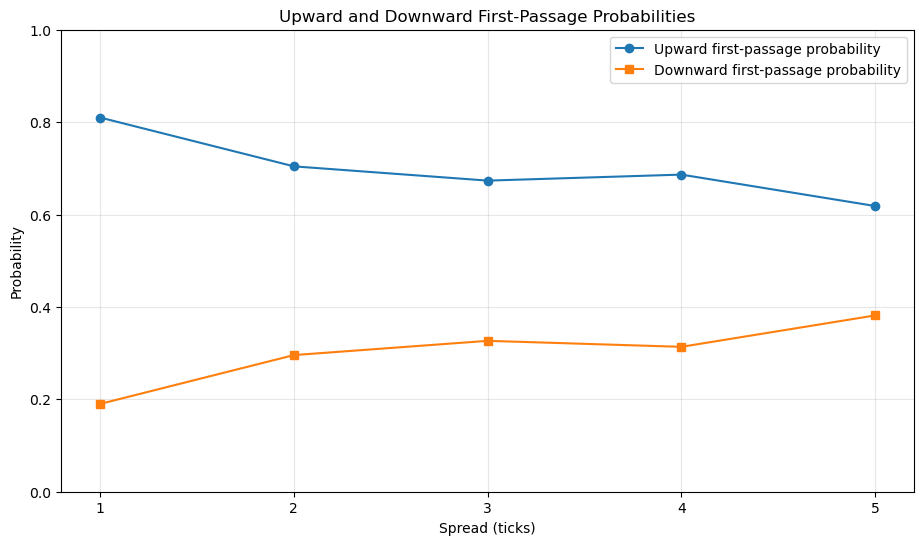


Part 7 results saved successfully as 'part7_first_passage_probabilities.csv'.

PART 7 EXECUTION COMPLETED.


In [83]:

# ============================================================
# PART 7: UPWARD AND DOWNWARD FIRST-PASSAGE PROBABILITIES
# Research paper:
# Lokin and Yu (2026)
# Fill Probabilities in a Limit Order Book with
# State-Dependent Stochastic Order Flows
#
# Numerical method:
# Finite-state continuous-time Markov chain (CTMC)
#
# Model:
# Model III - state-dependent birth-death queues
#
# IMPORTANT:
# This calculates eventual probabilities of the next
# mid-price movement (up or down), not fixed-horizon
# probabilities.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve, MatrixRankWarning

# ------------------------------------------------------------
# 7.1 CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "messages",
    "pre_book",
    "limit_rates",
    "market_rates",
    "cancellation_rates",
    "TICK_SIZE"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing: "
        + str(missing_variables)
        + ". Run the relevant earlier notebook cells first."
    )

print("All required Part 6 variables are available.")

# ------------------------------------------------------------
# 7.2 CHECK REQUIRED DATAFRAME COLUMNS
# ------------------------------------------------------------

required_limit_columns = [
    "Spread_Ticks",
    "Direction",
    "Distance_Ticks",
    "Arrival_Count",
    "Total_Limit_Size",
    "Arrival_Rate",
    "Reliable_Count"
]

required_market_columns = [
    "Spread_Ticks",
    "Market_Direction",
    "Market_Rate_Adjusted",
    "Reliable_Count"
]

required_cancel_columns = [
    "Spread_Ticks",
    "Direction",
    "Distance_Ticks",
    "Cancellation_Rate",
    "Reliable_Count"
]

required_book_columns = [
    "Ask_Price_1",
    "Bid_Price_1",
    "Ask_Volume_1",
    "Bid_Volume_1"
]

for name, df, required in [
    ("limit_rates", limit_rates, required_limit_columns),
    ("market_rates", market_rates, required_market_columns),
    ("cancellation_rates", cancellation_rates,
     required_cancel_columns),
    ("pre_book", pre_book, required_book_columns)
]:

    missing = [col for col in required if col not in df.columns]

    if missing:
        raise ValueError(
            f"{name} is missing columns: {missing}"
        )

print("All required columns are available.")

# ------------------------------------------------------------
# 7.3 PREPARE PARAMETER TABLES
# ------------------------------------------------------------

limit_rates = limit_rates.copy()
market_rates = market_rates.copy()
cancellation_rates = cancellation_rates.copy()

numeric_columns = {
    "limit_rates": [
        "Spread_Ticks", "Direction", "Distance_Ticks",
        "Arrival_Count", "Total_Limit_Size", "Arrival_Rate"
    ],
    "market_rates": [
        "Spread_Ticks", "Market_Direction",
        "Market_Rate_Adjusted"
    ],
    "cancellation_rates": [
        "Spread_Ticks", "Direction",
        "Distance_Ticks", "Cancellation_Rate"
    ]
}

for col in numeric_columns["limit_rates"]:
    limit_rates[col] = pd.to_numeric(
        limit_rates[col], errors="coerce"
    )

for col in numeric_columns["market_rates"]:
    market_rates[col] = pd.to_numeric(
        market_rates[col], errors="coerce"
    )

for col in numeric_columns["cancellation_rates"]:
    cancellation_rates[col] = pd.to_numeric(
        cancellation_rates[col], errors="coerce"
    )

# ------------------------------------------------------------
# 7.4 HELPER FUNCTION TO RETRIEVE RELIABLE PARAMETERS
# ------------------------------------------------------------

def get_reliable_rate(
    df,
    conditions,
    rate_column,
    table_name
):

    subset = df.copy()

    for column, value in conditions.items():
        subset = subset[
            np.isclose(
                subset[column].astype(float),
                float(value)
            )
        ]

    if len(subset) == 0:
        raise ValueError(
            f"No observation found in {table_name} "
            f"for {conditions}."
        )

    if len(subset) > 1:
        raise ValueError(
            f"Multiple rows found in {table_name} "
            f"for {conditions}. Check duplicate parameter rows."
        )

    row = subset.iloc[0]

    if not bool(row["Reliable_Count"]):
        raise ValueError(
            f"Unreliable parameter in {table_name} "
            f"for {conditions}."
        )

    rate = float(row[rate_column])

    if not np.isfinite(rate) or rate < 0:
        raise ValueError(
            f"Invalid rate in {table_name} "
            f"for {conditions}: {rate}"
        )

    return rate


# ------------------------------------------------------------
# 7.5 ESTIMATE AVERAGE LIMIT ORDER SIZE
# ------------------------------------------------------------

# Direction convention:
# +1 = Buy / Bid
# -1 = Sell / Ask

limit_size_summary = (
    limit_rates
    .groupby(["Spread_Ticks", "Direction"])
    .agg(
        Total_Size=("Total_Limit_Size", "sum"),
        Total_Count=("Arrival_Count", "sum")
    )
    .reset_index()
)

limit_size_summary["Average_Limit_Size"] = (
    limit_size_summary["Total_Size"]
    / limit_size_summary["Total_Count"].replace(0, np.nan)
)

print("\nAverage limit order sizes:")
display(limit_size_summary.head(10))


def get_average_limit_size(spread, direction):

    subset = limit_size_summary[
        (limit_size_summary["Spread_Ticks"] == spread)
        & (limit_size_summary["Direction"] == direction)
    ]

    if len(subset) != 1:
        raise ValueError(
            f"Average limit size unavailable for "
            f"spread={spread}, direction={direction}."
        )

    value = float(subset["Average_Limit_Size"].iloc[0])

    if not np.isfinite(value) or value <= 0:
        raise ValueError("Invalid average limit order size.")

    return value


# ------------------------------------------------------------
# 7.6 CALCULATE INITIAL QUEUE SIZE FOR EACH SPREAD
# ------------------------------------------------------------

# Convert displayed queue volume into equivalent
# average-limit-order units.
#
# This is an Amazon-data adaptation because LOBSTER
# records share volumes whereas the paper's model
# uses unit-sized orders.

book_data = pre_book.copy()

book_data["Spread_Ticks"] = (
    (
        pd.to_numeric(book_data["Ask_Price_1"],
                      errors="coerce")
        -
        pd.to_numeric(book_data["Bid_Price_1"],
                      errors="coerce")
    ) / TICK_SIZE
).round()

book_data["Ask_Volume_1"] = pd.to_numeric(
    book_data["Ask_Volume_1"], errors="coerce"
)

book_data["Bid_Volume_1"] = pd.to_numeric(
    book_data["Bid_Volume_1"], errors="coerce"
)

book_data = book_data[
    (book_data["Spread_Ticks"] > 0)
    & book_data["Ask_Volume_1"].notna()
    & book_data["Bid_Volume_1"].notna()
    & (book_data["Ask_Volume_1"] >= 0)
    & (book_data["Bid_Volume_1"] >= 0)
].copy()

queue_summary = (
    book_data
    .groupby("Spread_Ticks")
    .agg(
        Average_Ask_Volume=("Ask_Volume_1", "mean"),
        Average_Bid_Volume=("Bid_Volume_1", "mean"),
        Snapshot_Count=("Spread_Ticks", "size")
    )
    .reset_index()
)

print("\nAverage best-quote queue volumes:")
display(queue_summary.head(15))


# ------------------------------------------------------------
# 7.7 CONSTRUCT THE TWO QUEUE PROCESS PARAMETERS
# ------------------------------------------------------------

def get_queue_parameters(spread, direction):

    # Direction +1: Bid queue
    # Direction -1: Ask queue

    # Limit arrivals at the best quote occur at distance S.
    lambda_best = get_reliable_rate(
        limit_rates,
        {
            "Spread_Ticks": spread,
            "Direction": direction,
            "Distance_Ticks": spread
        },
        "Arrival_Rate",
        "limit_rates"
    )

    # Market-order direction refers to the resting
    # queue side in the LOBSTER message convention.
    mu_market = get_reliable_rate(
        market_rates,
        {
            "Spread_Ticks": spread,
            "Market_Direction": direction
        },
        "Market_Rate_Adjusted",
        "market_rates"
    )

    # Cancellation intensity per equivalent
    # average-limit-order unit.
    theta_cancel = get_reliable_rate(
        cancellation_rates,
        {
            "Spread_Ticks": spread,
            "Direction": direction,
            "Distance_Ticks": spread
        },
        "Cancellation_Rate",
        "cancellation_rates"
    )

    return lambda_best, mu_market, theta_cancel


# ------------------------------------------------------------
# 7.8 CALCULATE INSIDE-SPREAD ARRIVAL RATES
# ------------------------------------------------------------

def get_inside_spread_rate(spread, direction):

    # For spread S > 1, orders may arrive inside
    # the spread at distances 1, 2, ..., S-1.

    if spread <= 1:
        return 0.0

    total_rate = 0.0

    for distance in range(1, spread):

        rate = get_reliable_rate(
            limit_rates,
            {
                "Spread_Ticks": spread,
                "Direction": direction,
                "Distance_Ticks": distance
            },
            "Arrival_Rate",
            "limit_rates"
        )

        total_rate += rate

    return total_rate


# ------------------------------------------------------------
# 7.9 FINITE-STATE CTMC ABSORPTION PROBABILITY
# ------------------------------------------------------------

def calculate_upward_probability(
    initial_ask,
    initial_bid,
    lambda_ask,
    lambda_bid,
    mu_ask,
    mu_bid,
    theta_ask,
    theta_bid,
    inside_buy_rate,
    inside_sell_rate,
    queue_cap
):

    # State = (ask queue size, bid queue size)
    #
    # Upward absorption:
    #   1. Ask queue becomes empty.
    #   2. Buy limit order arrives inside the spread.
    #
    # Downward absorption:
    #   1. Bid queue becomes empty.
    #   2. Sell limit order arrives inside the spread.

    K = int(queue_cap)

    if initial_ask > K or initial_bid > K:
        raise ValueError(
            "Initial queue exceeds the selected queue cap."
        )

    number_states = K * K

    rows = []
    cols = []
    values = []

    upward_absorption = np.zeros(number_states)

    def state_index(ask, bid):
        return (ask - 1) * K + (bid - 1)

    for ask in range(1, K + 1):

        for bid in range(1, K + 1):

            index = state_index(ask, bid)

            total_outflow = 0.0

            # ----------------------------
            # ASK QUEUE: BIRTH
            # ----------------------------

            if ask < K and lambda_ask > 0:

                next_index = state_index(ask + 1, bid)

                rows.append(index)
                cols.append(next_index)
                values.append(-lambda_ask)

                total_outflow += lambda_ask

            # ----------------------------
            # ASK QUEUE: DEATH
            # ----------------------------

            ask_death = mu_ask + theta_ask * ask

            total_outflow += ask_death

            if ask > 1:

                next_index = state_index(ask - 1, bid)

                rows.append(index)
                cols.append(next_index)
                values.append(-ask_death)

            else:

                upward_absorption[index] += ask_death

            # ----------------------------
            # BID QUEUE: BIRTH
            # ----------------------------

            if bid < K and lambda_bid > 0:

                next_index = state_index(ask, bid + 1)

                rows.append(index)
                cols.append(next_index)
                values.append(-lambda_bid)

                total_outflow += lambda_bid

            # ----------------------------
            # BID QUEUE: DEATH
            # ----------------------------

            bid_death = mu_bid + theta_bid * bid

            total_outflow += bid_death

            if bid > 1:

                next_index = state_index(ask, bid - 1)

                rows.append(index)
                cols.append(next_index)
                values.append(-bid_death)

            # ----------------------------
            # INSIDE-SPREAD ARRIVALS
            # ----------------------------

            total_outflow += inside_buy_rate
            total_outflow += inside_sell_rate

            # A buy order inside the spread causes
            # an upward price movement.
            upward_absorption[index] += inside_buy_rate

            # A sell order inside the spread causes
            # a downward price movement.
            #
            # It contributes to total outflow but
            # not upward absorption.

            # ----------------------------
            # DIAGONAL GENERATOR ENTRY
            # ----------------------------

            rows.append(index)
            cols.append(index)
            values.append(total_outflow)

    # The matrix is -Q, where Q is the transient
    # generator of the joint two-queue process.

    matrix = coo_matrix(
        (values, (rows, cols)),
        shape=(number_states, number_states)
    ).tocsr()

    with warnings.catch_warnings():

        warnings.simplefilter("error", MatrixRankWarning)

        probabilities = spsolve(
            matrix,
            upward_absorption
        )

    initial_index = state_index(
        int(initial_ask),
        int(initial_bid)
    )

    result = float(probabilities[initial_index])

    if not np.isfinite(result):
        raise ValueError(
            "The CTMC solution is not finite."
        )

    if result < -1e-7 or result > 1 + 1e-7:
        raise ValueError(
            f"Invalid probability produced: {result}"
        )

    return float(np.clip(result, 0, 1))


# ------------------------------------------------------------
# 7.10 CALCULATE PROBABILITIES FOR EACH SPREAD STATE
# ------------------------------------------------------------

results = []
skipped_states = []

for _, queue_row in queue_summary.iterrows():

    spread = int(queue_row["Spread_Ticks"])

    try:

        # Side-specific average limit order sizes.
        avg_sell_size = get_average_limit_size(
            spread, -1
        )

        avg_buy_size = get_average_limit_size(
            spread, 1
        )

        # Initial queues in equivalent order units.
        initial_ask = max(
            1,
            int(round(
                queue_row["Average_Ask_Volume"]
                / avg_sell_size
            ))
        )

        initial_bid = max(
            1,
            int(round(
                queue_row["Average_Bid_Volume"]
                / avg_buy_size
            ))
        )

        # Best ask queue parameters.
        lambda_ask, mu_ask, theta_ask = (
            get_queue_parameters(spread, -1)
        )

        # Best bid queue parameters.
        lambda_bid, mu_bid, theta_bid = (
            get_queue_parameters(spread, 1)
        )

        # Inside-spread arrival rates.
        # Buy inside-spread arrivals cause upward moves.
        inside_buy_rate = get_inside_spread_rate(
            spread, 1
        )

        # Sell inside-spread arrivals cause downward moves.
        inside_sell_rate = get_inside_spread_rate(
            spread, -1
        )

        # Select a finite queue cap.
        max_initial = max(initial_ask, initial_bid)

        cap_1 = max(
            30,
            int(np.ceil(3 * max_initial + 15))
        )

        if cap_1 > 120:
            raise ValueError(
                "Initial queue is too large for the "
                "current finite-state implementation."
            )

        cap_2 = 2 * cap_1

        # Solve at two queue caps to assess truncation sensitivity.
        probability_1 = calculate_upward_probability(
            initial_ask,
            initial_bid,
            lambda_ask,
            lambda_bid,
            mu_ask,
            mu_bid,
            theta_ask,
            theta_bid,
            inside_buy_rate,
            inside_sell_rate,
            cap_1
        )

        probability_2 = calculate_upward_probability(
            initial_ask,
            initial_bid,
            lambda_ask,
            lambda_bid,
            mu_ask,
            mu_bid,
            theta_ask,
            theta_bid,
            inside_buy_rate,
            inside_sell_rate,
            cap_2
        )

        cap_difference = abs(
            probability_2 - probability_1
        )

        upward_probability = probability_2

        downward_probability = (
            1.0 - upward_probability
        )

        results.append({

            "Spread_Ticks": spread,

            "Initial_Ask_Queue_Units": initial_ask,

            "Initial_Bid_Queue_Units": initial_bid,

            "Ask_Limit_Rate": lambda_ask,

            "Bid_Limit_Rate": lambda_bid,

            "Ask_Market_Rate": mu_ask,

            "Bid_Market_Rate": mu_bid,

            "Ask_Cancellation_Rate": theta_ask,

            "Bid_Cancellation_Rate": theta_bid,

            "Inside_Buy_Rate": inside_buy_rate,

            "Inside_Sell_Rate": inside_sell_rate,

            "Upward_Probability": upward_probability,

            "Downward_Probability": downward_probability,

            "Probability_Sum": (
                upward_probability
                + downward_probability
            ),

            "Queue_Cap": cap_2,

            "Cap_Sensitivity": cap_difference,

            "Reliable_Cap_Result": (
                cap_difference <= 0.005
            ),

            "Snapshot_Count": int(
                queue_row["Snapshot_Count"]
            )

        })

        print(
            f"Spread {spread}: "
            f"Up = {upward_probability:.6f}, "
            f"Down = {downward_probability:.6f}, "
            f"Cap difference = {cap_difference:.6f}"
        )

    except (ValueError, KeyError, ZeroDivisionError) as error:

        skipped_states.append({

            "Spread_Ticks": spread,

            "Reason": str(error)

        })

        print(
            f"Spread {spread} skipped: {error}"
        )


# ------------------------------------------------------------
# 7.11 CREATE FINAL FIRST-PASSAGE RESULTS TABLE
# ------------------------------------------------------------

first_passage_results = pd.DataFrame(results)

if first_passage_results.empty:

    print(
        "\nNo spread states could be calculated. "
        "Inspect the skipped-state reasons and Part 6 estimates."
    )

else:

    print("\n" + "=" * 75)
    print("PART 7: FIRST-PASSAGE PROBABILITY RESULTS")
    print("=" * 75)

    display(first_passage_results)

    print("\nProbability validation:")

    print(
        "All probabilities between 0 and 1:",
        bool(
            (
                (first_passage_results["Upward_Probability"] >= 0)
                &
                (first_passage_results["Upward_Probability"] <= 1)
                &
                (first_passage_results["Downward_Probability"] >= 0)
                &
                (first_passage_results["Downward_Probability"] <= 1)
            ).all()
        )
    )

    print(
        "All probability sums equal 1:",
        bool(
            np.allclose(
                first_passage_results["Probability_Sum"],
                1.0,
                atol=1e-7
            )
        )
    )

    print(
        "All queue-cap checks within tolerance:",
        bool(
            first_passage_results[
                "Reliable_Cap_Result"
            ].all()
        )
    )


# ------------------------------------------------------------
# 7.12 DISPLAY SKIPPED STATES
# ------------------------------------------------------------

skipped_states = pd.DataFrame(skipped_states)

print("\nSkipped spread states:")

if skipped_states.empty:

    print("No spread states were skipped.")

else:

    display(skipped_states)


# ------------------------------------------------------------
# 7.13 VISUALISE UPWARD AND DOWNWARD PROBABILITIES
# ------------------------------------------------------------

if not first_passage_results.empty:

    plot_data = first_passage_results.sort_values(
        "Spread_Ticks"
    )

    plt.figure(figsize=(11, 6))

    plt.plot(
        plot_data["Spread_Ticks"],
        plot_data["Upward_Probability"],
        marker="o",
        label="Upward first-passage probability"
    )

    plt.plot(
        plot_data["Spread_Ticks"],
        plot_data["Downward_Probability"],
        marker="s",
        label="Downward first-passage probability"
    )

    plt.xlabel("Spread (ticks)")
    plt.ylabel("Probability")

    plt.title(
        "Upward and Downward First-Passage Probabilities"
    )

    plt.ylim(0, 1)

    plt.xticks(
        plot_data["Spread_Ticks"]
    )

    plt.grid(True, alpha=0.3)

    plt.legend()

    plt.show()


# ------------------------------------------------------------
# 7.14 SAVE RESULTS
# ------------------------------------------------------------

if not first_passage_results.empty:

    first_passage_results.to_csv(
        "part7_first_passage_probabilities.csv",
        index=False
    )

    print(
        "\nPart 7 results saved successfully as "
        "'part7_first_passage_probabilities.csv'."
    )

print("\nPART 7 EXECUTION COMPLETED.")


In [87]:

# ============================================================
# PART 8: MODEL VALIDATION AND DIAGNOSTICS
# Amazon Limit Order Book - First Passage Model
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("PART 8: MODEL VALIDATION AND DIAGNOSTICS")
print("=" * 70)

# ------------------------------------------------------------
# 8.1 Check that the required Part 6 and Part 7 results exist
# ------------------------------------------------------------

required_objects = [
    "first_passage_results",
    "limit_rates",
    "market_rates",
    "cancellation_rates"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "The following required objects are missing: "
        + ", ".join(missing_objects)
        + ". Run Parts 6 and 7 first."
    )

# Work on copies so the original results are not modified
fp = first_passage_results.copy()
lr = limit_rates.copy()
mr = market_rates.copy()
cr = cancellation_rates.copy()

print("\nRequired objects found successfully.")

# ------------------------------------------------------------
# 8.2 Check required columns
# ------------------------------------------------------------

required_fp_columns = [
    "Spread_Ticks",
    "Upward_Probability",
    "Downward_Probability",
    "Probability_Sum",
    "Initial_Ask_Queue_Units",
    "Initial_Bid_Queue_Units",
    "Queue_Cap",
    "Cap_Sensitivity",
    "Reliable_Cap_Result",
    "Snapshot_Count"
]

required_limit_columns = [
    "Arrival_Count",
    "Time_in_State",
    "Arrival_Rate"
]

required_market_columns = [
    "Market_Rate_Raw",
    "Market_Rate_Adjusted",
    "Market_Size_Ratio"
]

required_cancel_columns = [
    "Cancellation_Rate"
]

def check_columns(df, required, table_name):
    missing = [col for col in required if col not in df.columns]

    if missing:
        raise ValueError(
            f"{table_name} is missing columns: {missing}"
        )

check_columns(fp, required_fp_columns, "first_passage_results")
check_columns(lr, required_limit_columns, "limit_rates")
check_columns(mr, required_market_columns, "market_rates")
check_columns(cr, required_cancel_columns, "cancellation_rates")

print("All required columns are present.")

# ------------------------------------------------------------
# 8.3 Validate first-passage probabilities
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("8.3 FIRST-PASSAGE PROBABILITY VALIDATION")
print("=" * 70)

fp["Calculated_Probability_Sum"] = (
    fp["Upward_Probability"] +
    fp["Downward_Probability"]
)

fp["Probability_Sum_Error"] = abs(
    fp["Calculated_Probability_Sum"] - 1.0
)

fp["Probability_In_Range"] = (
    fp["Upward_Probability"].between(0, 1) &
    fp["Downward_Probability"].between(0, 1)
)

fp["Probability_Sum_Valid"] = (
    fp["Probability_Sum_Error"] < 1e-6
)

fp["Probability_Valid"] = (
    fp["Probability_In_Range"] &
    fp["Probability_Sum_Valid"]
)

probability_columns = [
    "Spread_Ticks",
    "Upward_Probability",
    "Downward_Probability",
    "Calculated_Probability_Sum",
    "Probability_Valid"
]

print(fp[probability_columns].to_string(index=False))

# ------------------------------------------------------------
# 8.4 Check limit-order arrival-rate calculations
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("8.4 LIMIT-ORDER ARRIVAL-RATE VALIDATION")
print("=" * 70)

lr["Recalculated_Arrival_Rate"] = np.where(
    lr["Time_in_State"] > 0,
    lr["Arrival_Count"] / lr["Time_in_State"],
    np.nan
)

lr["Arrival_Rate_Difference"] = abs(
    lr["Arrival_Rate"] - lr["Recalculated_Arrival_Rate"]
)

lr["Arrival_Rate_Valid"] = (
    np.isfinite(lr["Arrival_Rate"]) &
    np.isfinite(lr["Recalculated_Arrival_Rate"]) &
    (lr["Arrival_Rate_Difference"] < 1e-6)
)

print(
    "Number of limit-order rate rows:",
    len(lr)
)

print(
    "Rows with valid recalculated rates:",
    int(lr["Arrival_Rate_Valid"].sum())
)

print(
    "Rows with invalid or mismatched rates:",
    int((~lr["Arrival_Rate_Valid"]).sum())
)

# Show mismatches, if any
limit_rate_errors = lr.loc[
    ~lr["Arrival_Rate_Valid"],
    [
        "Arrival_Count",
        "Time_in_State",
        "Arrival_Rate",
        "Recalculated_Arrival_Rate",
        "Arrival_Rate_Difference"
    ]
]

if len(limit_rate_errors) > 0:
    print("\nLimit-order rate mismatches:")
    print(limit_rate_errors.head(10).to_string(index=False))
else:
    print("All limit-order arrival rates pass this calculation check.")

# ------------------------------------------------------------
# 8.5 Check market-order size adjustment
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("8.5 MARKET-ORDER RATE ADJUSTMENT VALIDATION")
print("=" * 70)

mr["Recalculated_Market_Rate"] = (
    mr["Market_Rate_Raw"] *
    mr["Market_Size_Ratio"]
)

mr["Market_Rate_Difference"] = abs(
    mr["Market_Rate_Adjusted"] -
    mr["Recalculated_Market_Rate"]
)

mr["Market_Adjustment_Valid"] = (
    np.isfinite(mr["Market_Rate_Adjusted"]) &
    np.isfinite(mr["Recalculated_Market_Rate"]) &
    (mr["Market_Rate_Difference"] < 1e-6)
)

print(
    "Number of market-order rate rows:",
    len(mr)
)

print(
    "Rows with valid size adjustments:",
    int(mr["Market_Adjustment_Valid"].sum())
)

print(
    "Rows with invalid or mismatched adjustments:",
    int((~mr["Market_Adjustment_Valid"]).sum())
)

market_rate_errors = mr.loc[
    ~mr["Market_Adjustment_Valid"],
    [
        "Market_Rate_Raw",
        "Market_Size_Ratio",
        "Market_Rate_Adjusted",
        "Recalculated_Market_Rate",
        "Market_Rate_Difference"
    ]
]

if len(market_rate_errors) > 0:
    print("\nMarket-rate adjustment mismatches:")
    print(market_rate_errors.head(10).to_string(index=False))
else:
    print("All market-order size adjustments pass this calculation check.")

# ------------------------------------------------------------
# 8.6 Check rate values
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("8.6 PARAMETER RATE VALIDATION")
print("=" * 70)

rate_checks = {
    "Limit-order arrival rates": lr["Arrival_Rate"],
    "Adjusted market-order rates": mr["Market_Rate_Adjusted"],
    "Cancellation rates": cr["Cancellation_Rate"]
}

rate_summary = []

for rate_name, values in rate_checks.items():

    values = pd.to_numeric(values, errors="coerce")

    finite = np.isfinite(values)
    nonnegative = values >= 0

    rate_summary.append({
        "Rate_Type": rate_name,
        "Number_of_Rows": len(values),
        "Finite_Rows": int(finite.sum()),
        "Nonnegative_Rows": int(nonnegative.sum()),
        "Invalid_Rows": int((~(finite & nonnegative)).sum()),
        "Minimum_Rate": values.min(),
        "Maximum_Rate": values.max()
    })

rate_summary = pd.DataFrame(rate_summary)

print(rate_summary.to_string(index=False))

# ------------------------------------------------------------
# 8.7 Check queue-cap sensitivity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("8.7 QUEUE-CAP SENSITIVITY VALIDATION")
print("=" * 70)

fp["Cap_Sensitivity_Valid"] = (
    np.isfinite(fp["Cap_Sensitivity"]) &
    (fp["Cap_Sensitivity"] <= 0.005) &
    (fp["Reliable_Cap_Result"] == True)
)

cap_columns = [
    "Spread_Ticks",
    "Queue_Cap",
    "Cap_Sensitivity",
    "Reliable_Cap_Result",
    "Cap_Sensitivity_Valid"
]

print(fp[cap_columns].to_string(index=False))

# ------------------------------------------------------------
# 8.8 Check initial queue sizes and snapshot counts
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("8.8 INITIAL QUEUE AND SAMPLE-SIZE VALIDATION")
print("=" * 70)

fp["Initial_Queues_Valid"] = (
    (fp["Initial_Ask_Queue_Units"] > 0) &
    (fp["Initial_Bid_Queue_Units"] > 0)
)

fp["Snapshot_Count_Valid"] = (
    fp["Snapshot_Count"] > 0
)

queue_columns = [
    "Spread_Ticks",
    "Initial_Ask_Queue_Units",
    "Initial_Bid_Queue_Units",
    "Snapshot_Count",
    "Initial_Queues_Valid",
    "Snapshot_Count_Valid"
]

print(fp[queue_columns].to_string(index=False))

# ------------------------------------------------------------
# 8.9 Overall validation summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("8.9 OVERALL VALIDATION SUMMARY")
print("=" * 70)

validation_summary = pd.DataFrame([
    {
        "Validation": "First-passage probabilities",
        "Passed": int(fp["Probability_Valid"].sum()),
        "Total": len(fp)
    },
    {
        "Validation": "Limit-order rate calculations",
        "Passed": int(lr["Arrival_Rate_Valid"].sum()),
        "Total": len(lr)
    },
    {
        "Validation": "Market-order size adjustments",
        "Passed": int(mr["Market_Adjustment_Valid"].sum()),
        "Total": len(mr)
    },
    {
        "Validation": "Queue-cap sensitivity",
        "Passed": int(fp["Cap_Sensitivity_Valid"].sum()),
        "Total": len(fp)
    },
    {
        "Validation": "Initial queue sizes",
        "Passed": int(fp["Initial_Queues_Valid"].sum()),
        "Total": len(fp)
    },
    {
        "Validation": "Snapshot counts",
        "Passed": int(fp["Snapshot_Count_Valid"].sum()),
        "Total": len(fp)
    }
])

validation_summary["Failed"] = (
    validation_summary["Total"] -
    validation_summary["Passed"]
)

print(validation_summary.to_string(index=False))

# ------------------------------------------------------------
# 8.10 Final validation status
# ------------------------------------------------------------

all_probability_checks_pass = bool(
    fp["Probability_Valid"].all()
)

all_cap_checks_pass = bool(
    fp["Cap_Sensitivity_Valid"].all()
)

all_limit_checks_pass = bool(
    lr["Arrival_Rate_Valid"].all()
)

all_market_checks_pass = bool(
    mr["Market_Adjustment_Valid"].all()
)

all_initial_queue_checks_pass = bool(
    fp["Initial_Queues_Valid"].all()
)

all_snapshot_checks_pass = bool(
    fp["Snapshot_Count_Valid"].all()
)

print("\n" + "=" * 70)
print("FINAL PART 8 STATUS")
print("=" * 70)

checks = {
    "Probability validation": all_probability_checks_pass,
    "Queue-cap sensitivity": all_cap_checks_pass,
    "Limit-order rate calculation": all_limit_checks_pass,
    "Market-order size adjustment": all_market_checks_pass,
    "Initial queue sizes": all_initial_queue_checks_pass,
    "Snapshot counts": all_snapshot_checks_pass
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'CHECK REQUIRED'}")

if all(checks.values()):
    print(
        "\nAll implemented numerical and calculation checks passed."
    )
    print(
        "This does not by itself establish that the model assumptions "
        "or paper replication are correct."
    )
else:
    print(
        "\nSome checks require investigation before final interpretation."
    )

# ------------------------------------------------------------
# 8.11 Save validation outputs
# ------------------------------------------------------------

validation_summary.to_csv(
    "Part8_Validation_Summary.csv",
    index=False
)

fp.to_csv(
    "Part8_First_Passage_Validation.csv",
    index=False
)

rate_summary.to_csv(
    "Part8_Rate_Validation.csv",
    index=False
)

print("\nPart 8 validation files saved successfully.")


PART 8: MODEL VALIDATION AND DIAGNOSTICS

Required objects found successfully.
All required columns are present.

8.3 FIRST-PASSAGE PROBABILITY VALIDATION
 Spread_Ticks  Upward_Probability  Downward_Probability  Calculated_Probability_Sum  Probability_Valid
            1            0.809916              0.190084                         1.0               True
            2            0.704265              0.295735                         1.0               True
            3            0.673400              0.326600                         1.0               True
            4            0.686397              0.313603                         1.0               True
            5            0.618411              0.381589                         1.0               True

8.4 LIMIT-ORDER ARRIVAL-RATE VALIDATION
Number of limit-order rate rows: 3360
Rows with valid recalculated rates: 3350
Rows with invalid or mismatched rates: 10

Limit-order rate mismatches:
 Arrival_Count  Time_in_State  Arri

In [89]:
validation_summary

,Validation,Passed,Total,Failed
0,First-passage probabilities,5,5,0
1,Limit-order rate calculations,3350,3360,10
2,Market-order size adjustments,77,77,0
3,Queue-cap sensitivity,5,5,0
4,Initial queue sizes,5,5,0
5,Snapshot counts,5,5,0


In [93]:

# PART 8A: INVESTIGATE THE 10 LIMIT-ORDER RATE MISMATCHES

mismatch_rows = lr.loc[
    ~lr["Arrival_Rate_Valid"]
].copy()

print("Number of mismatched rows:", len(mismatch_rows))

display(
    mismatch_rows[
        [
            "Spread_Ticks",
            "Direction",
            "Distance_Ticks",
            "Arrival_Count",
            "Time_in_State",
            "Arrival_Rate",
            "Recalculated_Arrival_Rate",
            "Arrival_Rate_Difference"
        ]
    ].to_string(index=False)
)

print("\nMaximum difference:")
print(mismatch_rows["Arrival_Rate_Difference"].max())

print("\nMinimum exposure time:")
print(mismatch_rows["Time_in_State"].min())

print("\nAre any exposure times zero or negative?")
print((mismatch_rows["Time_in_State"] <= 0).any())


Number of mismatched rows: 10


' Spread_Ticks  Direction  Distance_Ticks  Arrival_Count  Time_in_State  Arrival_Rate  Recalculated_Arrival_Rate  Arrival_Rate_Difference\n           61         -1            35.0              1            0.0           inf                        NaN                      NaN\n           61         -1            36.0              1            0.0           inf                        NaN                      NaN\n           61         -1            37.0              1            0.0           inf                        NaN                      NaN\n           61         -1            38.0              2            0.0           inf                        NaN                      NaN\n           61         -1            42.0              1            0.0           inf                        NaN                      NaN\n           61         -1            44.0              1            0.0           inf                        NaN                      NaN\n           74          1         


Maximum difference:
nan

Minimum exposure time:
0.0

Are any exposure times zero or negative?
True


PART 9: INITIAL QUEUE SIZE SENSITIVITY ANALYSIS
Part 7 results found.
Number of spread states: 5

Queue sizes to be tested: [1, 2, 3, 5, 10]

Sensitivity calculations completed.
Total scenarios calculated: 145

ORIGINAL PART 7 VS PART 9 COMPARISON


' Spread_Ticks  Initial_Ask_Queue_Units  Initial_Bid_Queue_Units  Upward_Probability_Part9  Downward_Probability_Part9  Probability_Sum  Is_Original_Queue  Queue_Cap  Upward_Probability_Part7  Downward_Probability_Part7  Upward_Difference  Downward_Difference\n            1                        2                        4                  0.809916                    0.190084              1.0               True         60                  0.809916                    0.190084       2.220446e-16         2.220446e-16\n            2                        2                        4                  0.704265                    0.295735              1.0               True         60                  0.704265                    0.295735       1.110223e-16         1.110223e-16\n            3                        2                        4                  0.673400                    0.326600              1.0               True         60                  0.673400                    0.326600 


PART 9 PROBABILITY VALIDATION
Valid scenarios: 145
Invalid scenarios: 0

SENSITIVITY SUMMARY BY SPREAD


' Spread_Ticks  Scenario_Count  Minimum_Upward_Probability  Maximum_Upward_Probability  Mean_Upward_Probability  Minimum_Downward_Probability  Maximum_Downward_Probability  All_Probabilities_Valid  Upward_Probability_Range\n            1              30                    0.045093                    0.987060                 0.583310                      0.012940                      0.954907                     True                  0.941967\n            2              30                    0.164749                    0.843276                 0.554858                      0.156724                      0.835251                     True                  0.678526\n            3              30                    0.199769                    0.808330                 0.540111                      0.191670                      0.800231                     True                  0.608560\n            4              25                    0.242408                    0.799847                 0.553

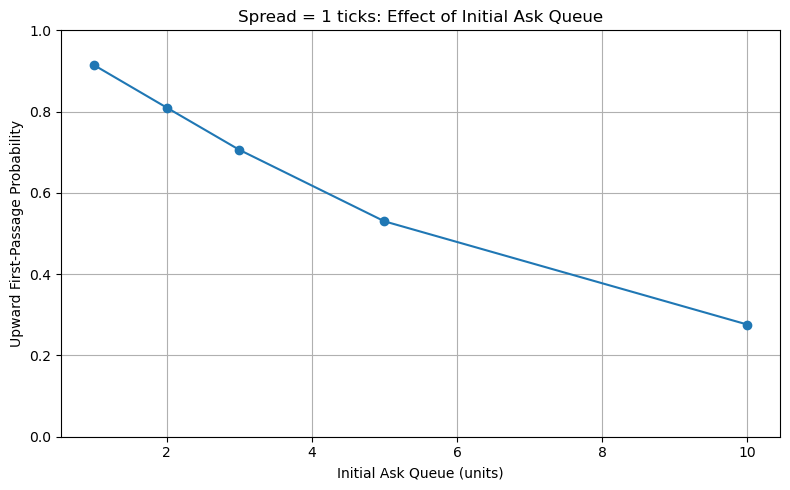

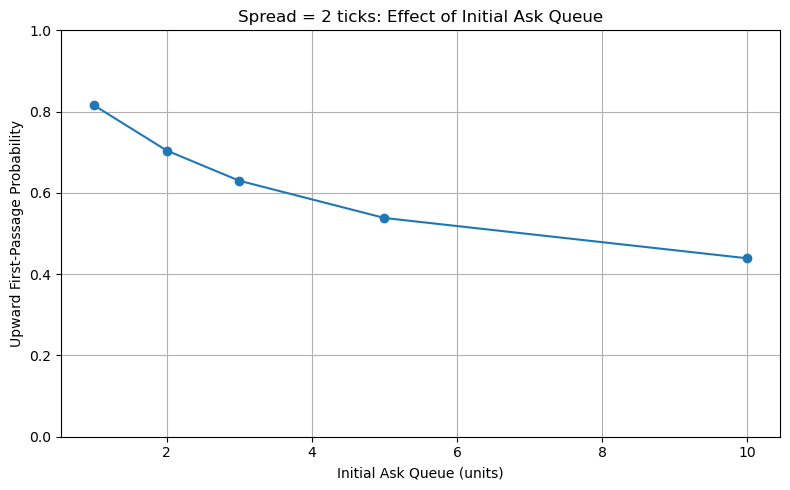

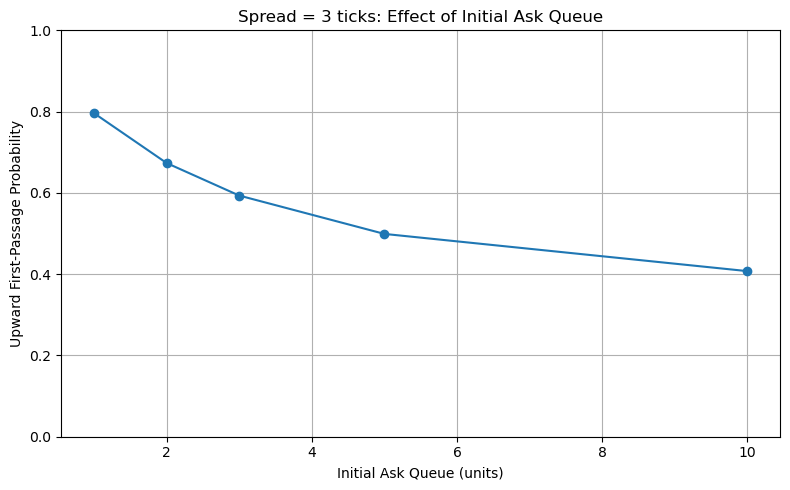

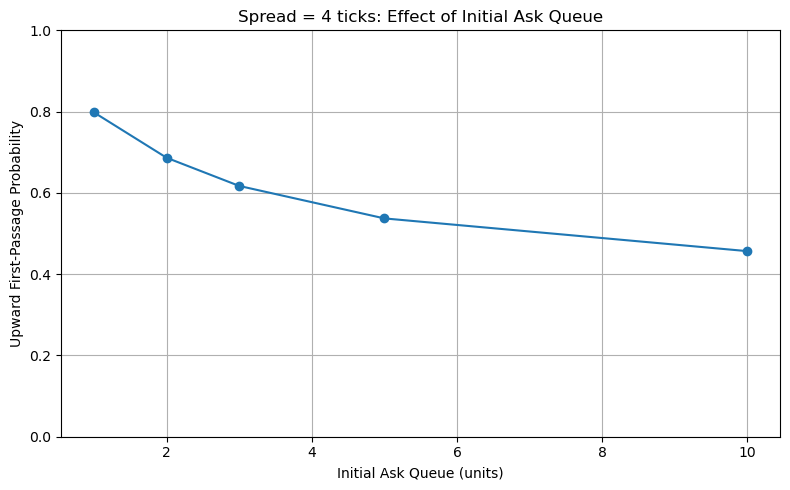

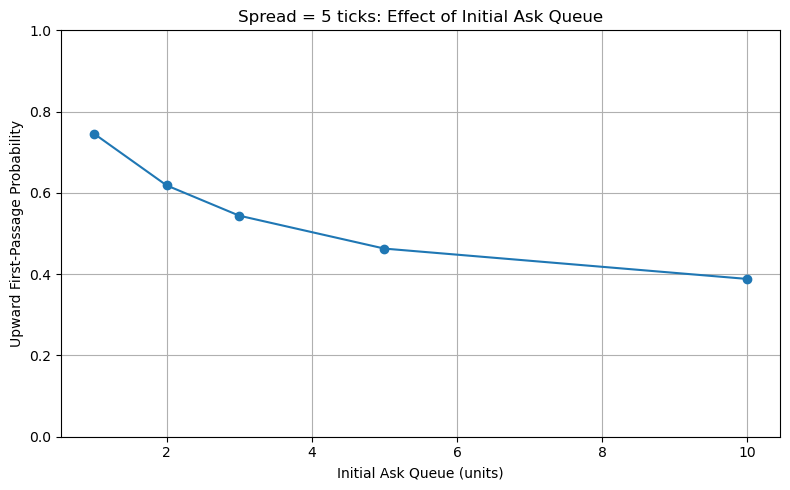

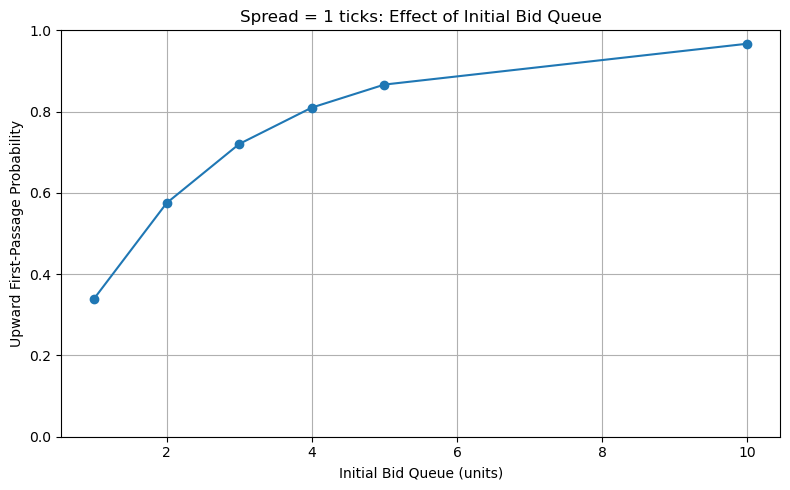

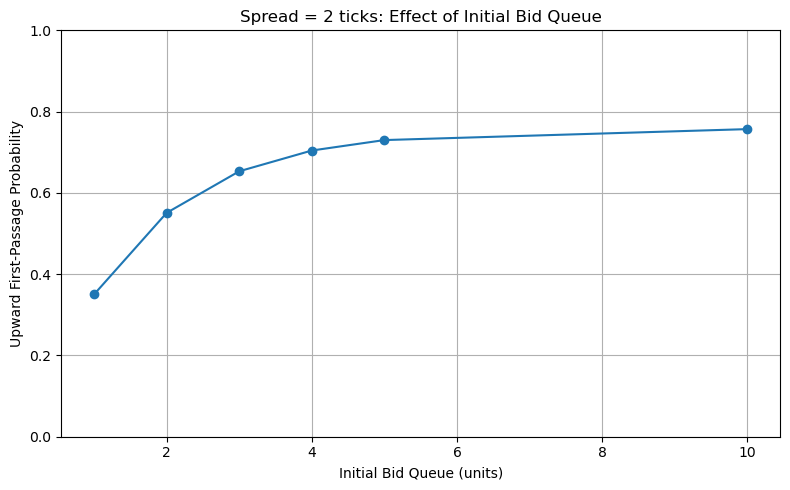

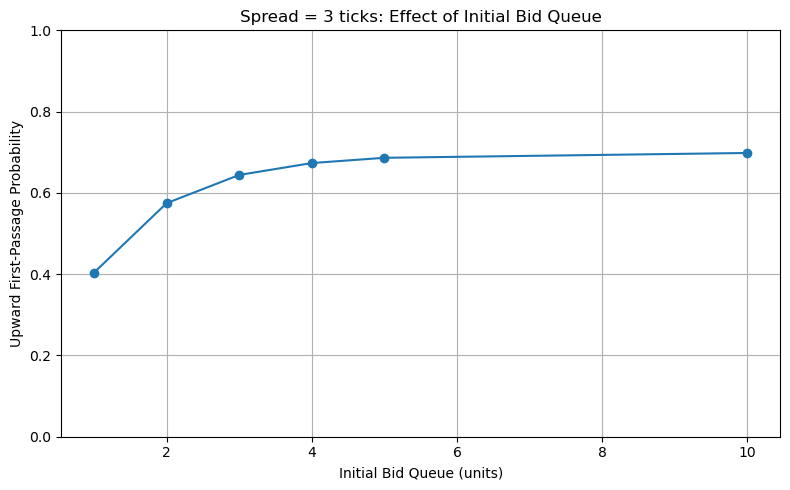

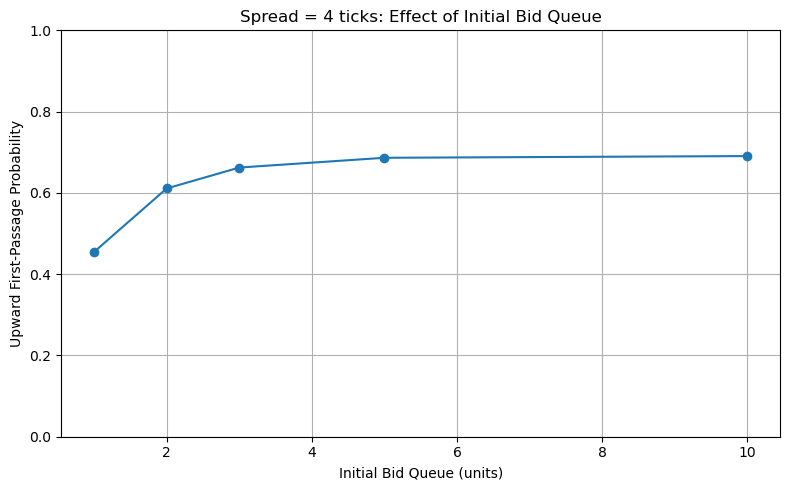

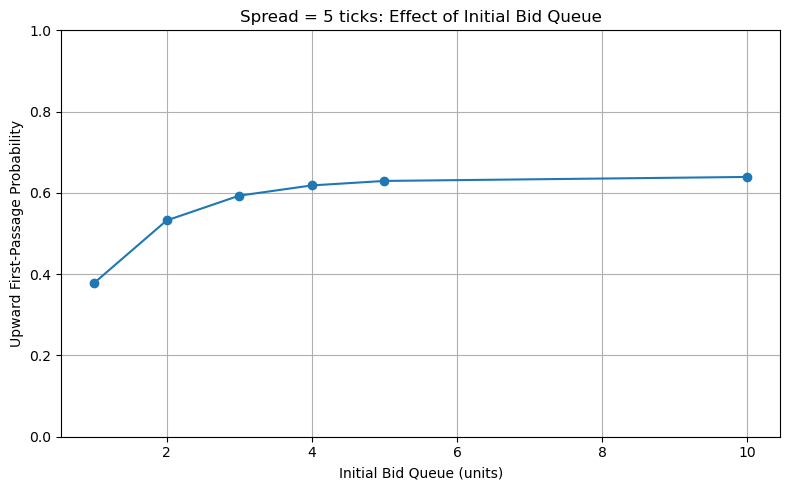


PART 9 COMPLETED
Detailed results saved:
1. Part9_Queue_Sensitivity_Results.csv
2. Part9_Queue_Sensitivity_Summary.csv
3. Part9_Part7_Comparison.csv

Please inspect the comparison and sensitivity summary.


In [95]:

# ============================================================
# PART 9: INITIAL QUEUE SIZE SENSITIVITY ANALYSIS
# Amazon Limit Order Book - First Passage Model
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve
from scipy.sparse import SparseEfficiencyWarning

import warnings

print("=" * 75)
print("PART 9: INITIAL QUEUE SIZE SENSITIVITY ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 9.1 Check required Part 7 results
# ------------------------------------------------------------

if "first_passage_results" not in globals():
    raise NameError(
        "first_passage_results not found. Run Part 7 first."
    )

fp9 = first_passage_results.copy()

required_columns = [
    "Spread_Ticks",
    "Initial_Ask_Queue_Units",
    "Initial_Bid_Queue_Units",
    "Ask_Limit_Rate",
    "Bid_Limit_Rate",
    "Ask_Market_Rate",
    "Bid_Market_Rate",
    "Ask_Cancellation_Rate",
    "Bid_Cancellation_Rate",
    "Inside_Buy_Rate",
    "Inside_Sell_Rate",
    "Upward_Probability",
    "Queue_Cap"
]

missing_columns = [
    col for col in required_columns
    if col not in fp9.columns
]

if missing_columns:
    raise ValueError(
        "Missing columns in first_passage_results: "
        + str(missing_columns)
    )

print("Part 7 results found.")
print("Number of spread states:", len(fp9))


# ------------------------------------------------------------
# 9.2 Define the CTMC probability solver
# ------------------------------------------------------------

def calculate_upward_probability(
    initial_ask,
    initial_bid,
    ask_limit_rate,
    bid_limit_rate,
    ask_market_rate,
    bid_market_rate,
    ask_cancellation_rate,
    bid_cancellation_rate,
    inside_buy_rate,
    inside_sell_rate,
    queue_cap
):
    """
    Calculate eventual upward first-passage probability
    for a specified initial ask and bid queue size.

    Queue states:
        ask queue = 1, ..., queue_cap
        bid queue = 1, ..., queue_cap

    Upward absorption:
        Ask queue depletion or inside-spread buy arrival.

    Downward absorption:
        Bid queue depletion or inside-spread sell arrival.

    Birth rates:
        Ask and bid limit-order arrivals.

    Death rates:
        Market-order rate + cancellation rate * queue size.

    Births are suppressed at the queue cap, matching
    the reflecting upper-bound convention used in Part 7.
    """

    rates = [
        ask_limit_rate,
        bid_limit_rate,
        ask_market_rate,
        bid_market_rate,
        ask_cancellation_rate,
        bid_cancellation_rate,
        inside_buy_rate,
        inside_sell_rate
    ]

    rates = np.asarray(rates, dtype=float)

    if not np.all(np.isfinite(rates)):
        raise ValueError("One or more model rates are not finite.")

    if np.any(rates < 0):
        raise ValueError("Model rates cannot be negative.")

    K = int(queue_cap)

    if K < 1:
        raise ValueError("Queue cap must be at least 1.")

    initial_ask = int(initial_ask)
    initial_bid = int(initial_bid)

    if not (1 <= initial_ask <= K):
        raise ValueError("Initial ask queue is outside the queue cap.")

    if not (1 <= initial_bid <= K):
        raise ValueError("Initial bid queue is outside the queue cap.")

    # Number of transient states
    number_of_states = K * K

    # State (ask, bid) maps to a matrix index
    def state_index(ask, bid):
        return (ask - 1) * K + (bid - 1)

    # Sparse transient generator matrix
    Q = lil_matrix(
        (number_of_states, number_of_states),
        dtype=float
    )

    # Upward absorption rate for each transient state
    upward_absorption = np.zeros(number_of_states)

    # Build the generator
    for ask in range(1, K + 1):

        for bid in range(1, K + 1):

            i = state_index(ask, bid)

            total_out_rate = 0.0
            upward_rate = inside_buy_rate

            # Inside-spread buy arrival:
            # immediate upward price move
            total_out_rate += inside_buy_rate

            # Inside-spread sell arrival:
            # immediate downward price move
            total_out_rate += inside_sell_rate

            # ------------------------------------------------
            # Ask-side limit-order arrival: queue birth
            # ------------------------------------------------

            if ask < K and ask_limit_rate > 0:

                j = state_index(ask + 1, bid)

                Q[i, j] += ask_limit_rate
                total_out_rate += ask_limit_rate

            # At the cap, additional births are suppressed.

            # ------------------------------------------------
            # Bid-side limit-order arrival: queue birth
            # ------------------------------------------------

            if bid < K and bid_limit_rate > 0:

                j = state_index(ask, bid + 1)

                Q[i, j] += bid_limit_rate
                total_out_rate += bid_limit_rate

            # ------------------------------------------------
            # Ask-side depletion
            # ------------------------------------------------

            ask_death_rate = (
                ask_market_rate +
                ask_cancellation_rate * ask
            )

            total_out_rate += ask_death_rate

            if ask == 1:
                # Ask queue becomes empty: upward absorption
                upward_rate += ask_death_rate

            else:
                j = state_index(ask - 1, bid)
                Q[i, j] += ask_death_rate

            # ------------------------------------------------
            # Bid-side depletion
            # ------------------------------------------------

            bid_death_rate = (
                bid_market_rate +
                bid_cancellation_rate * bid
            )

            total_out_rate += bid_death_rate

            if bid > 1:
                j = state_index(ask, bid - 1)
                Q[i, j] += bid_death_rate

            # If bid == 1, bid depletion is downward absorption.

            # Diagonal element
            Q[i, i] = -total_out_rate

            upward_absorption[i] = upward_rate

    # Solve:
    #       (-Q) h = r_up
    #
    # h is the probability of eventual upward absorption.

    A = (-Q).tocsc()

    with warnings.catch_warnings():
        warnings.simplefilter("error", SparseEfficiencyWarning)
        upward_probabilities = spsolve(
            A,
            upward_absorption
        )

    # Extract probability for the requested initial queues
    result_index = state_index(initial_ask, initial_bid)

    upward_probability = float(
        upward_probabilities[result_index]
    )

    downward_probability = 1.0 - upward_probability

    if not (
        np.isfinite(upward_probability) and
        np.isfinite(downward_probability)
    ):
        raise ValueError("The calculated probabilities are not finite.")

    if (
        upward_probability < -1e-6 or
        upward_probability > 1 + 1e-6
    ):
        raise ValueError(
            "Calculated upward probability is outside [0, 1]."
        )

    return upward_probability, downward_probability


# ------------------------------------------------------------
# 9.3 Define the queue sizes to test
# ------------------------------------------------------------

test_queue_sizes = [1, 2, 3, 5, 10]

sensitivity_records = []

print("\nQueue sizes to be tested:", test_queue_sizes)


# ------------------------------------------------------------
# 9.4 Calculate probabilities for every spread
# ------------------------------------------------------------

for _, row in fp9.iterrows():

    spread = int(row["Spread_Ticks"])

    queue_cap = int(row["Queue_Cap"])

    original_ask = int(row["Initial_Ask_Queue_Units"])
    original_bid = int(row["Initial_Bid_Queue_Units"])

    # Include the original Part 7 queue sizes in the test grid
    ask_values = sorted(
        set(test_queue_sizes + [original_ask])
    )

    bid_values = sorted(
        set(test_queue_sizes + [original_bid])
    )

    # Check that the requested queue sizes fit the cap
    ask_values = [q for q in ask_values if 1 <= q <= queue_cap]
    bid_values = [q for q in bid_values if 1 <= q <= queue_cap]

    # Read the fitted Part 7 rates
    model_rates = {
        "ask_limit_rate": float(row["Ask_Limit_Rate"]),
        "bid_limit_rate": float(row["Bid_Limit_Rate"]),
        "ask_market_rate": float(row["Ask_Market_Rate"]),
        "bid_market_rate": float(row["Bid_Market_Rate"]),
        "ask_cancellation_rate": float(row["Ask_Cancellation_Rate"]),
        "bid_cancellation_rate": float(row["Bid_Cancellation_Rate"]),
        "inside_buy_rate": float(row["Inside_Buy_Rate"]),
        "inside_sell_rate": float(row["Inside_Sell_Rate"]),
        "queue_cap": queue_cap
    }

    # Test every ask/bid queue-size combination
    for ask_q in ask_values:

        for bid_q in bid_values:

            up, down = calculate_upward_probability(
                initial_ask=ask_q,
                initial_bid=bid_q,
                **model_rates
            )

            sensitivity_records.append({
                "Spread_Ticks": spread,
                "Initial_Ask_Queue_Units": ask_q,
                "Initial_Bid_Queue_Units": bid_q,
                "Upward_Probability": up,
                "Downward_Probability": down,
                "Probability_Sum": up + down,
                "Is_Original_Queue": (
                    ask_q == original_ask and
                    bid_q == original_bid
                ),
                "Queue_Cap": queue_cap
            })

sensitivity_results = pd.DataFrame(sensitivity_records)

print("\nSensitivity calculations completed.")
print("Total scenarios calculated:", len(sensitivity_results))


# ------------------------------------------------------------
# 9.5 Compare original Part 7 results with Part 9
# ------------------------------------------------------------

original_comparison = sensitivity_results.loc[
    sensitivity_results["Is_Original_Queue"]
].copy()

original_comparison = original_comparison.merge(
    fp9[
        [
            "Spread_Ticks",
            "Upward_Probability",
            "Downward_Probability"
        ]
    ],
    on="Spread_Ticks",
    suffixes=("_Part9", "_Part7")
)

original_comparison["Upward_Difference"] = abs(
    original_comparison["Upward_Probability_Part9"] -
    original_comparison["Upward_Probability_Part7"]
)

original_comparison["Downward_Difference"] = abs(
    original_comparison["Downward_Probability_Part9"] -
    original_comparison["Downward_Probability_Part7"]
)

print("\n" + "=" * 75)
print("ORIGINAL PART 7 VS PART 9 COMPARISON")
print("=" * 75)

display(original_comparison.to_string(index=False))


# ------------------------------------------------------------
# 9.6 Validate probability bounds and sums
# ------------------------------------------------------------

sensitivity_results["Probability_Valid"] = (
    sensitivity_results["Upward_Probability"].between(0, 1) &
    sensitivity_results["Downward_Probability"].between(0, 1) &
    (
        abs(sensitivity_results["Probability_Sum"] - 1.0)
        < 1e-6
    )
)

print("\n" + "=" * 75)
print("PART 9 PROBABILITY VALIDATION")
print("=" * 75)

print(
    "Valid scenarios:",
    int(sensitivity_results["Probability_Valid"].sum())
)

print(
    "Invalid scenarios:",
    int((~sensitivity_results["Probability_Valid"]).sum())
)


# ------------------------------------------------------------
# 9.7 Summarise sensitivity by spread
# ------------------------------------------------------------

sensitivity_summary = (
    sensitivity_results
    .groupby("Spread_Ticks")
    .agg(
        Scenario_Count=("Upward_Probability", "count"),
        Minimum_Upward_Probability=("Upward_Probability", "min"),
        Maximum_Upward_Probability=("Upward_Probability", "max"),
        Mean_Upward_Probability=("Upward_Probability", "mean"),
        Minimum_Downward_Probability=("Downward_Probability", "min"),
        Maximum_Downward_Probability=("Downward_Probability", "max"),
        All_Probabilities_Valid=("Probability_Valid", "all")
    )
    .reset_index()
)

sensitivity_summary["Upward_Probability_Range"] = (
    sensitivity_summary["Maximum_Upward_Probability"] -
    sensitivity_summary["Minimum_Upward_Probability"]
)

print("\n" + "=" * 75)
print("SENSITIVITY SUMMARY BY SPREAD")
print("=" * 75)

display(sensitivity_summary.to_string(index=False))


# ------------------------------------------------------------
# 9.8 Plot upward probability against initial ask queue
#     while holding bid queue at its original value
# ------------------------------------------------------------

for _, row in fp9.iterrows():

    spread = int(row["Spread_Ticks"])
    original_bid = int(row["Initial_Bid_Queue_Units"])

    plot_data = sensitivity_results[
        (sensitivity_results["Spread_Ticks"] == spread) &
        (sensitivity_results["Initial_Bid_Queue_Units"] == original_bid)
    ].sort_values("Initial_Ask_Queue_Units")

    plt.figure(figsize=(8, 5))

    plt.plot(
        plot_data["Initial_Ask_Queue_Units"],
        plot_data["Upward_Probability"],
        marker="o"
    )

    plt.xlabel("Initial Ask Queue (units)")
    plt.ylabel("Upward First-Passage Probability")
    plt.title(
        f"Spread = {spread} ticks: "
        "Effect of Initial Ask Queue"
    )

    plt.ylim(0, 1)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 9.9 Plot upward probability against initial bid queue
#     while holding ask queue at its original value
# ------------------------------------------------------------

for _, row in fp9.iterrows():

    spread = int(row["Spread_Ticks"])
    original_ask = int(row["Initial_Ask_Queue_Units"])

    plot_data = sensitivity_results[
        (sensitivity_results["Spread_Ticks"] == spread) &
        (sensitivity_results["Initial_Ask_Queue_Units"] == original_ask)
    ].sort_values("Initial_Bid_Queue_Units")

    plt.figure(figsize=(8, 5))

    plt.plot(
        plot_data["Initial_Bid_Queue_Units"],
        plot_data["Upward_Probability"],
        marker="o"
    )

    plt.xlabel("Initial Bid Queue (units)")
    plt.ylabel("Upward First-Passage Probability")
    plt.title(
        f"Spread = {spread} ticks: "
        "Effect of Initial Bid Queue"
    )

    plt.ylim(0, 1)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 9.10 Save Part 9 outputs
# ------------------------------------------------------------

sensitivity_results.to_csv(
    "Part9_Queue_Sensitivity_Results.csv",
    index=False
)

sensitivity_summary.to_csv(
    "Part9_Queue_Sensitivity_Summary.csv",
    index=False
)

original_comparison.to_csv(
    "Part9_Part7_Comparison.csv",
    index=False
)

print("\n" + "=" * 75)
print("PART 9 COMPLETED")
print("=" * 75)

print("Detailed results saved:")
print("1. Part9_Queue_Sensitivity_Results.csv")
print("2. Part9_Queue_Sensitivity_Summary.csv")
print("3. Part9_Part7_Comparison.csv")

print("\nPlease inspect the comparison and sensitivity summary.")


In [103]:

# ============================================================
# PART 10: EMPIRICAL VALIDATION OF ORDER-FLOW DIRECTION
# Amazon Limit Order Book
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("PART 10: ORDER-FLOW DIRECTION VALIDATION")
print("=" * 75)

# ------------------------------------------------------------
# 10.1 Check required variables
# ------------------------------------------------------------

required_variables = ["messages", "book"]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise NameError(
        "Missing variables: " + str(missing)
    )

if len(messages) != len(book):
    raise ValueError(
        "Message and order-book row counts differ. "
        "Check LOBSTER alignment before proceeding."
    )

# ------------------------------------------------------------
# 10.2 Align pre-event and post-event order books
# ------------------------------------------------------------

pre10 = book.iloc[:-1].reset_index(drop=True)
post10 = book.iloc[1:].reset_index(drop=True)

msg10 = messages.iloc[1:].copy().reset_index(drop=True)

if not (
    len(pre10) == len(post10) == len(msg10)
):
    raise ValueError("Pre-book, post-book and message lengths do not match.")

# ------------------------------------------------------------
# 10.3 Check required columns
# ------------------------------------------------------------

required_message_columns = [
    "Type",
    "Direction",
    "Price",
    "Size"
]

required_book_columns = [
    "Ask_Price_1",
    "Bid_Price_1"
]

for col in required_message_columns:
    if col not in msg10.columns:
        raise ValueError(
            f"Message column missing: {col}"
        )

for col in required_book_columns:
    if col not in pre10.columns or col not in post10.columns:
        raise ValueError(
            f"Order-book column missing: {col}"
        )

# ------------------------------------------------------------
# 10.4 Identify visible execution events (Type 4)
# ------------------------------------------------------------

execution = msg10[
    pd.to_numeric(msg10["Type"], errors="coerce") == 4
].copy()

execution_indices = execution.index

print("\nTotal visible execution events:", len(execution))

# ------------------------------------------------------------
# 10.5 Extract pre-event and post-event best quotes
# ------------------------------------------------------------

execution["Pre_Best_Ask"] = (
    pre10.loc[execution_indices, "Ask_Price_1"].to_numpy()
)

execution["Pre_Best_Bid"] = (
    pre10.loc[execution_indices, "Bid_Price_1"].to_numpy()
)

execution["Post_Best_Ask"] = (
    post10.loc[execution_indices, "Ask_Price_1"].to_numpy()
)

execution["Post_Best_Bid"] = (
    post10.loc[execution_indices, "Bid_Price_1"].to_numpy()
)

execution["Pre_Mid"] = (
    execution["Pre_Best_Ask"] +
    execution["Pre_Best_Bid"]
) / 2

execution["Post_Mid"] = (
    execution["Post_Best_Ask"] +
    execution["Post_Best_Bid"]
) / 2

# ------------------------------------------------------------
# 10.6 Identify the direction of the execution
# ------------------------------------------------------------

execution["Direction"] = pd.to_numeric(
    execution["Direction"],
    errors="coerce"
)

execution["Execution_Price"] = pd.to_numeric(
    execution["Price"],
    errors="coerce"
)

# LOBSTER convention:
# Direction -1 = sell/resting ask-side order
# Direction +1 = buy/resting bid-side order

execution["Expected_Side"] = np.select(
    [
        execution["Direction"] == -1,
        execution["Direction"] == 1
    ],
    [
        "Ask",
        "Bid"
    ],
    default="Unknown"
)

# ------------------------------------------------------------
# 10.7 Check whether execution price belongs to expected side
# ------------------------------------------------------------

ask_price_columns = [
    f"Ask_Price_{i}" for i in range(1, 11)
    if f"Ask_Price_{i}" in pre10.columns
]

bid_price_columns = [
    f"Bid_Price_{i}" for i in range(1, 11)
    if f"Bid_Price_{i}" in pre10.columns
]

if not ask_price_columns or not bid_price_columns:
    raise ValueError(
        "Could not find the 10-level ask and bid price columns."
    )

pre_ask_prices = pre10.loc[
    execution_indices, ask_price_columns
].to_numpy(dtype=float)

pre_bid_prices = pre10.loc[
    execution_indices, bid_price_columns
].to_numpy(dtype=float)

event_prices = execution["Execution_Price"].to_numpy(dtype=float)

ask_matches = np.any(
    np.isclose(
        pre_ask_prices,
        event_prices[:, None],
        rtol=0,
        atol=1e-8
    ) & (pre_ask_prices > 0),
    axis=1
)

bid_matches = np.any(
    np.isclose(
        pre_bid_prices,
        event_prices[:, None],
        rtol=0,
        atol=1e-8
    ) & (pre_bid_prices > 0),
    axis=1
)

execution["Matches_Ask_Book"] = ask_matches
execution["Matches_Bid_Book"] = bid_matches

execution["Expected_Side_Match"] = np.select(
    [
        execution["Direction"] == -1,
        execution["Direction"] == 1
    ],
    [
        execution["Matches_Ask_Book"],
        execution["Matches_Bid_Book"]
    ],
    default=False
)

# ------------------------------------------------------------
# 10.8 Measure the actual best-quote movement
# ------------------------------------------------------------

execution["Mid_Price_Change"] = (
    execution["Post_Mid"] -
    execution["Pre_Mid"]
)

execution["Price_Move"] = np.select(
    [
        execution["Mid_Price_Change"] > 0,
        execution["Mid_Price_Change"] < 0
    ],
    [
        "Upward",
        "Downward"
    ],
    default="Unchanged"
)

execution["Ask_Quote_Change"] = (
    execution["Post_Best_Ask"] -
    execution["Pre_Best_Ask"]
)

execution["Bid_Quote_Change"] = (
    execution["Post_Best_Bid"] -
    execution["Pre_Best_Bid"]
)

# Expected direction under the implemented model:
# Direction -1: ask depletion -> upward move
# Direction +1: bid depletion -> downward move

execution["Expected_Move"] = np.select(
    [
        execution["Direction"] == -1,
        execution["Direction"] == 1
    ],
    [
        "Upward",
        "Downward"
    ],
    default="Unknown"
)

execution["Direction_Mapping_Consistent"] = (
    (execution["Expected_Move"] == "Upward") &
    (execution["Price_Move"] == "Upward")
) | (
    (execution["Expected_Move"] == "Downward") &
    (execution["Price_Move"] == "Downward")
)

# ------------------------------------------------------------
# 10.9 Summarise execution-price matching by direction
# ------------------------------------------------------------

direction_summary = (
    execution
    .groupby("Direction", dropna=False)
    .agg(
        Execution_Count=("Execution_Price", "count"),
        Ask_Book_Matches=("Matches_Ask_Book", "sum"),
        Bid_Book_Matches=("Matches_Bid_Book", "sum"),
        Expected_Side_Matches=("Expected_Side_Match", "sum")
    )
    .reset_index()
)

direction_summary["Expected_Side_Match_Percentage"] = (
    direction_summary["Expected_Side_Matches"] /
    direction_summary["Execution_Count"] * 100
)

print("\n" + "=" * 75)
print("EXECUTION PRICE AND ORDER-BOOK SIDE VALIDATION")
print("=" * 75)

display(direction_summary)

# ------------------------------------------------------------
# 10.10 Summarise actual price moves by direction
# ------------------------------------------------------------

move_summary = pd.crosstab(
    execution["Direction"],
    execution["Price_Move"],
    margins=True
)

print("\n" + "=" * 75)
print("PRICE MOVEMENTS AFTER VISIBLE EXECUTIONS")
print("=" * 75)

display(move_summary)

# ------------------------------------------------------------
# 10.11 Analyse quote movements separately
# ------------------------------------------------------------

quote_summary = (
    execution
    .groupby("Direction", dropna=False)
    .agg(
        Execution_Count=("Execution_Price", "count"),
        Ask_Quote_Increases=(
            "Ask_Quote_Change",
            lambda x: int((x > 0).sum())
        ),
        Ask_Quote_Decreases=(
            "Ask_Quote_Change",
            lambda x: int((x < 0).sum())
        ),
        Bid_Quote_Increases=(
            "Bid_Quote_Change",
            lambda x: int((x > 0).sum())
        ),
        Bid_Quote_Decreases=(
            "Bid_Quote_Change",
            lambda x: int((x < 0).sum())
        )
    )
    .reset_index()
)

print("\n" + "=" * 75)
print("BEST QUOTE MOVEMENT DIAGNOSTICS")
print("=" * 75)

display(quote_summary)

# ------------------------------------------------------------
# 10.12 Examine events that do not match expected side
# ------------------------------------------------------------

unexpected_side_events = execution[
    ~execution["Expected_Side_Match"]
].copy()

print("\nEvents not matching the expected book side:")
print(len(unexpected_side_events))

if len(unexpected_side_events) > 0:

    display(
        unexpected_side_events[
            [
                "Direction",
                "Execution_Price",
                "Expected_Side",
                "Matches_Ask_Book",
                "Matches_Bid_Book",
                "Pre_Best_Ask",
                "Pre_Best_Bid"
            ]
        ].head(15)
    )

# ------------------------------------------------------------
# 10.13 Examine executions followed by actual mid-price moves
# ------------------------------------------------------------

actual_moves = execution[
    execution["Price_Move"] != "Unchanged"
].copy()

if len(actual_moves) > 0:

    actual_move_summary = pd.crosstab(
        actual_moves["Direction"],
        actual_moves["Price_Move"],
        margins=True
    )

    print("\n" + "=" * 75)
    print("DIRECTION MAPPING AMONG EVENTS WITH PRICE MOVEMENTS")
    print("=" * 75)

    display(actual_move_summary)

else:
    print(
        "\nNo best-mid-price movements were detected "
        "immediately after visible executions."
    )

# ------------------------------------------------------------
# 10.14 Save diagnostic outputs
# ------------------------------------------------------------

execution.to_csv(
    "Part10_Visible_Execution_Diagnostics.csv",
    index=False
)

direction_summary.to_csv(
    "Part10_Direction_Summary.csv",
    index=False
)

move_summary.to_csv(
    "Part10_Price_Move_Summary.csv"
)

quote_summary.to_csv(
    "Part10_Quote_Move_Summary.csv",
    index=False
)

print("\n" + "=" * 75)
print("PART 10 COMPLETED")
print("=" * 75)

print("Saved:")
print("1. Part10_Visible_Execution_Diagnostics.csv")
print("2. Part10_Direction_Summary.csv")
print("3. Part10_Price_Move_Summary.csv")
print("4. Part10_Quote_Move_Summary.csv")


PART 10: ORDER-FLOW DIRECTION VALIDATION

Total visible execution events: 8974

EXECUTION PRICE AND ORDER-BOOK SIDE VALIDATION


,Direction,Execution_Count,Ask_Book_Matches,Bid_Book_Matches,Expected_Side_Matches,Expected_Side_Match_Percentage
0,-1,4808,4808,0,4808,100.0
1,1,4166,0,4166,4166,100.0



PRICE MOVEMENTS AFTER VISIBLE EXECUTIONS


Price_Move,Downward,Unchanged,Upward,All
Direction,,,,
-1,0,2440,2368,4808
1,1871,2295,0,4166
All,1871,4735,2368,8974



BEST QUOTE MOVEMENT DIAGNOSTICS


,Direction,Execution_Count,Ask_Quote_Increases,Ask_Quote_Decreases,Bid_Quote_Increases,Bid_Quote_Decreases
0,-1,4808,2368,0,0,0
1,1,4166,0,0,0,1871



Events not matching the expected book side:
0

DIRECTION MAPPING AMONG EVENTS WITH PRICE MOVEMENTS


Price_Move,Downward,Upward,All
Direction,,,
-1,0,2368,2368
1,1871,0,1871
All,1871,2368,4239



PART 10 COMPLETED
Saved:
1. Part10_Visible_Execution_Diagnostics.csv
2. Part10_Direction_Summary.csv
3. Part10_Price_Move_Summary.csv
4. Part10_Quote_Move_Summary.csv


In [105]:
print(
    sensitivity_results.groupby("Spread_Ticks").size()
)

Spread_Ticks
1    30
2    30
3    30
4    25
5    30
dtype: int64


In [107]:
# ============================================================
# PART 11: AUDIT QUEUE SENSITIVITY SCENARIOS
# ============================================================

import pandas as pd
import numpy as np

print("PART 11: QUEUE SENSITIVITY AUDIT")
print("=" * 60)

# 1. Inspect available columns
print("\n1. Columns in sensitivity_results:")
print(sensitivity_results.columns.tolist())

# 2. Check scenario counts
print("\n2. Number of scenarios for each spread:")
scenario_counts = (
    sensitivity_results
    .groupby("Spread_Ticks")
    .size()
    .rename("Scenario_Count")
    .reset_index()
)

print(scenario_counts.to_string(index=False))

# 3. Check duplicate queue combinations
possible_ask_columns = [
    "Initial_Ask_Queue",
    "Ask_Queue",
    "Ask_Queue_Size"
]

possible_bid_columns = [
    "Initial_Bid_Queue",
    "Bid_Queue",
    "Bid_Queue_Size"
]

ask_col = next(
    (c for c in possible_ask_columns if c in sensitivity_results.columns),
    None
)

bid_col = next(
    (c for c in possible_bid_columns if c in sensitivity_results.columns),
    None
)

if ask_col is None or bid_col is None:
    print("\nCould not automatically identify the queue-size columns.")
    print("Please share the column names printed above.")
else:
    print(f"\n3. Ask queue column: {ask_col}")
    print(f"   Bid queue column: {bid_col}")

    duplicate_rows = sensitivity_results[
        sensitivity_results.duplicated(
            subset=["Spread_Ticks", ask_col, bid_col],
            keep=False
        )
    ]

    print("\nDuplicate spread/queue combinations:")
    if duplicate_rows.empty:
        print("No duplicate combinations found.")
    else:
        print(duplicate_rows[
            ["Spread_Ticks", ask_col, bid_col]
        ].sort_values(
            ["Spread_Ticks", ask_col, bid_col]
        ).to_string(index=False))

    # 4. Display the actual queue combinations for each spread
    print("\n4. Queue combinations by spread:")

    for spread in sorted(sensitivity_results["Spread_Ticks"].unique()):
        subset = sensitivity_results[
            sensitivity_results["Spread_Ticks"] == spread
        ]

        combinations = (
            subset[[ask_col, bid_col]]
            .drop_duplicates()
            .sort_values([ask_col, bid_col])
        )

        print(f"\nSpread = {spread}")
        print(combinations.to_string(index=False))
        print("Number of unique combinations:", len(combinations))

# 5. Check missing values
print("\n5. Missing values:")
print(sensitivity_results.isnull().sum())

# 6. Check probability validity, if the expected columns exist
print("\n6. Probability validation:")

probability_columns = [
    c for c in ["Upward_Probability", "Downward_Probability"]
    if c in sensitivity_results.columns
]

if len(probability_columns) == 2:
    valid_bounds = (
        sensitivity_results[probability_columns]
        .ge(0).all().all()
        and
        sensitivity_results[probability_columns]
        .le(1).all().all()
    )

    probability_sum = (
        sensitivity_results["Upward_Probability"]
        + sensitivity_results["Downward_Probability"]
    )

    valid_sums = np.allclose(
        probability_sum,
        1.0,
        atol=1e-6
    )

    print("All probabilities between 0 and 1:", valid_bounds)
    print("All probability pairs sum to 1:", valid_sums)
else:
    print("Probability columns not automatically identified.")
    print("Available columns:", sensitivity_results.columns.tolist())

print("\nPART 11 AUDIT COMPLETED")

PART 11: QUEUE SENSITIVITY AUDIT

1. Columns in sensitivity_results:
['Spread_Ticks', 'Initial_Ask_Queue_Units', 'Initial_Bid_Queue_Units', 'Upward_Probability', 'Downward_Probability', 'Probability_Sum', 'Is_Original_Queue', 'Queue_Cap', 'Probability_Valid']

2. Number of scenarios for each spread:
 Spread_Ticks  Scenario_Count
            1              30
            2              30
            3              30
            4              25
            5              30

Could not automatically identify the queue-size columns.
Please share the column names printed above.

5. Missing values:
Spread_Ticks               0
Initial_Ask_Queue_Units    0
Initial_Bid_Queue_Units    0
Upward_Probability         0
Downward_Probability       0
Probability_Sum            0
Is_Original_Queue          0
Queue_Cap                  0
Probability_Valid          0
dtype: int64

6. Probability validation:
All probabilities between 0 and 1: True
All probability pairs sum to 1: True

PART 11 AUDIT CO

In [109]:
# ============================================================
# PART 11B: CORRECTED QUEUE COMBINATION AUDIT
# ============================================================

ask_col = "Initial_Ask_Queue_Units"
bid_col = "Initial_Bid_Queue_Units"

print("CORRECTED QUEUE SENSITIVITY AUDIT")
print("=" * 60)

for spread in sorted(sensitivity_results["Spread_Ticks"].unique()):

    subset = sensitivity_results[
        sensitivity_results["Spread_Ticks"] == spread
    ]

    combinations = (
        subset[[ask_col, bid_col]]
        .drop_duplicates()
        .sort_values([ask_col, bid_col])
    )

    duplicate_count = subset.duplicated(
        subset=[ask_col, bid_col]
    ).sum()

    print(f"\nSpread: {spread}")
    print("Total scenarios:", len(subset))
    print("Unique combinations:", len(combinations))
    print("Duplicate rows:", duplicate_count)

    print("\nQueue combinations:")
    print(combinations.to_string(index=False))

print("\nOriginal queue scenarios:")
print(
    sensitivity_results[
        sensitivity_results["Is_Original_Queue"] == True
    ][[
        "Spread_Ticks",
        ask_col,
        bid_col,
        "Upward_Probability",
        "Downward_Probability"
    ]].to_string(index=False)
)

print("\nCORRECTED AUDIT COMPLETED")

CORRECTED QUEUE SENSITIVITY AUDIT

Spread: 1
Total scenarios: 30
Unique combinations: 30
Duplicate rows: 0

Queue combinations:
 Initial_Ask_Queue_Units  Initial_Bid_Queue_Units
                       1                        1
                       1                        2
                       1                        3
                       1                        4
                       1                        5
                       1                       10
                       2                        1
                       2                        2
                       2                        3
                       2                        4
                       2                        5
                       2                       10
                       3                        1
                       3                        2
                       3                        3
                       3                        4
                      

In [111]:
# ============================================================
# PART 11C: VERIFY ORIGINAL QUEUES AGAINST PART 7
# ============================================================

print("PART 7 ORIGINAL RESULTS")
print("=" * 60)

print(first_passage_results.to_string(index=False))

print("\nPART 9 ORIGINAL QUEUE FLAGS")
print("=" * 60)

print(
    sensitivity_results[
        sensitivity_results["Is_Original_Queue"] == True
    ][[
        "Spread_Ticks",
        "Initial_Ask_Queue_Units",
        "Initial_Bid_Queue_Units",
        "Upward_Probability",
        "Downward_Probability"
    ]].to_string(index=False)
)


PART 7 ORIGINAL RESULTS
 Spread_Ticks  Initial_Ask_Queue_Units  Initial_Bid_Queue_Units  Ask_Limit_Rate  Bid_Limit_Rate  Ask_Market_Rate  Bid_Market_Rate  Ask_Cancellation_Rate  Bid_Cancellation_Rate  Inside_Buy_Rate  Inside_Sell_Rate  Upward_Probability  Downward_Probability  Probability_Sum  Queue_Cap  Cap_Sensitivity  Reliable_Cap_Result  Snapshot_Count
            1                        2                        4        1.707110        1.362056         3.693386         2.957385               0.512293               0.356790         0.000000          0.000000            0.809916              0.190084              1.0         60              0.0                 True            1605
            2                        2                        4        0.937571        0.810246         1.642069         2.116945               1.006399               0.160865         0.370398          0.462998            0.704265              0.295735              1.0         60              0.0         

In [113]:
%pip install streamlit scipy pandas numpy matplotlib
# ============================================================
# PART 12A: DASHBOARD DATA READINESS CHECK
# ============================================================

required_objects = [
    "first_passage_results",
    "sensitivity_results",
    "limit_rates",
    "market_rates",
    "cancellation_rates"
]

print("DASHBOARD DATA READINESS CHECK")
print("=" * 60)

missing_objects = []

for name in required_objects:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: Available | Type: {type(obj).__name__}")

        if isinstance(obj, pd.DataFrame):
            print("   Shape:", obj.shape)
            print("   Columns:", obj.columns.tolist())
    else:
        print(f"{name}: MISSING")
        missing_objects.append(name)

print("\n" + "=" * 60)

if not missing_objects:
    print("SUCCESS: All required dashboard data objects are available.")
else:
    print("Some objects are missing:", missing_objects)

Note: you may need to restart the kernel to use updated packages.
DASHBOARD DATA READINESS CHECK
first_passage_results: Available | Type: DataFrame
   Shape: (5, 18)
   Columns: ['Spread_Ticks', 'Initial_Ask_Queue_Units', 'Initial_Bid_Queue_Units', 'Ask_Limit_Rate', 'Bid_Limit_Rate', 'Ask_Market_Rate', 'Bid_Market_Rate', 'Ask_Cancellation_Rate', 'Bid_Cancellation_Rate', 'Inside_Buy_Rate', 'Inside_Sell_Rate', 'Upward_Probability', 'Downward_Probability', 'Probability_Sum', 'Queue_Cap', 'Cap_Sensitivity', 'Reliable_Cap_Result', 'Snapshot_Count']
sensitivity_results: Available | Type: DataFrame
   Shape: (145, 9)
   Columns: ['Spread_Ticks', 'Initial_Ask_Queue_Units', 'Initial_Bid_Queue_Units', 'Upward_Probability', 'Downward_Probability', 'Probability_Sum', 'Is_Original_Queue', 'Queue_Cap', 'Probability_Valid']
limit_rates: Available | Type: DataFrame
   Shape: (3360, 10)
   Columns: ['Spread_Ticks', 'Direction', 'Distance_Ticks', 'Arrival_Count', 'Average_Limit_Size', 'Total_Limit_Size'

In [115]:
# ============================================================
# PART 12B: EXPORT MODEL DATA FOR STREAMLIT DASHBOARD
# ============================================================

import os
import pandas as pd

# Create dashboard data folder
dashboard_folder = "AMZN_Dashboard_Data"
os.makedirs(dashboard_folder, exist_ok=True)

# DataFrames to export
dashboard_data = {
    "first_passage_results": first_passage_results,
    "sensitivity_results": sensitivity_results,
    "limit_rates": limit_rates,
    "market_rates": market_rates,
    "cancellation_rates": cancellation_rates
}

print("EXPORTING DASHBOARD DATA")
print("=" * 60)

for name, dataframe in dashboard_data.items():

    file_path = os.path.join(
        dashboard_folder,
        name + ".csv"
    )

    dataframe.to_csv(file_path, index=False)

    print(f"\nExported: {name}.csv")
    print("Rows:", len(dataframe))
    print("Columns:", len(dataframe.columns))
    print("File:", os.path.abspath(file_path))

print("\n" + "=" * 60)
print("PART 12B COMPLETED")
print("Dashboard data folder:", os.path.abspath(dashboard_folder))

EXPORTING DASHBOARD DATA

Exported: first_passage_results.csv
Rows: 5
Columns: 18
File: C:\Users\ADMIN\Desktop\lob statistics\AMZN_Dashboard_Data\first_passage_results.csv

Exported: sensitivity_results.csv
Rows: 145
Columns: 9
File: C:\Users\ADMIN\Desktop\lob statistics\AMZN_Dashboard_Data\sensitivity_results.csv

Exported: limit_rates.csv
Rows: 3360
Columns: 10
File: C:\Users\ADMIN\Desktop\lob statistics\AMZN_Dashboard_Data\limit_rates.csv

Exported: market_rates.csv
Rows: 77
Columns: 12
File: C:\Users\ADMIN\Desktop\lob statistics\AMZN_Dashboard_Data\market_rates.csv

Exported: cancellation_rates.csv
Rows: 2401
Columns: 11
File: C:\Users\ADMIN\Desktop\lob statistics\AMZN_Dashboard_Data\cancellation_rates.csv

PART 12B COMPLETED
Dashboard data folder: C:\Users\ADMIN\Desktop\lob statistics\AMZN_Dashboard_Data
